<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-14/lab-079-rbm-ising.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 079. A restricted Boltzmann machine trained on Ising configurations

A Monte Carlo simulation of the two-dimensional Ising model returns spin configurations drawn from the Gibbs distribution at a chosen temperature. Here such a set of configurations is the only information given to the learner, and the energy function and the temperature behind it are treated as unknown. The goal is a model distribution over spin configurations that assigns high probability to configurations like those in the data and from which we can draw new configurations with the same statistics. The model is a restricted Boltzmann machine (RBM), an energy-based model with visible units, which hold a spin configuration, and hidden units, which are never observed. Its biases and weights are learned from the data. We choose the number of hidden units, the step size and the length of the training.

Lab 078a and Lab 078 stored given patterns in a Hopfield network, with couplings fixed by a formula and spins that follow the sign of their local field, and Section 9 of Lab 078a compared the correlations of the data and of a small model in its learning rule (11). Equation (12) below is the same comparison for a model with hidden units. The RBM keeps the idea of an energy and of a field acting on each unit, makes the units stochastic, adds hidden units, and learns its parameters from examples. The Ising energy contains only couplings between neighbouring spins, so a model built on the known lattice would need no hidden units. We use the RBM because it is told neither the lattice nor the form of the interaction. The experiment tests how much of the physics such a general model extracts from configurations alone.

The energy of the RBM connects only visible with hidden units, so the units of one layer are independent once the other layer is fixed, and a whole layer is sampled in one step. The gradient of the log-likelihood is the difference between an average over the data and an average over the model, the positive and the negative phase [1,2]. Contrastive divergence [3] replaces the model average by the result of a few sampling steps started at the data. We check the independence within a layer, the form of the gradient and the effect of the sampling steps on a machine with four visible and three hidden units, small enough to list all of its 128 configurations. An RBM trained in this way on Ising configurations then generates new configurations, and we compare their magnetisation and energy with the data.

Section 1 loads the libraries and Section 2 produces the data. Section 3 treats the units, the RBM and its hidden units, Section 4 the gradient and Section 5 contrastive divergence. Section 6 trains one machine below and one above the critical temperature, Section 7 shows generated configurations and follows the sign of the magnetisation along the sampling chains, and Section 8 compares the histograms and summarises the core route. Sections 1 to 8 form the core route, which takes about two minutes. Section 9 is work at home and takes between 20 and 35 minutes, depending on the computer. It repeats the training with other numbers of sampling steps, adds a temperature next to the critical one, tests the role of the unit encoding, varies the number of hidden units, follows the sign changes and free energies during training and looks at the learned hidden units. Section 10 summarises the work at home and Section 11 contains exercises.

Ref. [4] trained RBMs on Monte Carlo configurations of the Ising model and compared thermodynamic observables of the generated configurations with the exact ones over a range of temperatures. Our study is narrower, with one lattice size, two temperatures and one training run per setting with fixed random seeds. All numbers of Sections 6 to 8 are therefore results of single runs.

## 1. Libraries

All computations use NumPy on the CPU, and Matplotlib draws the figures. The small machine is evaluated in double precision and the machine with 100 visible units in single precision. Every experiment has its own random generator with a fixed seed, so it can be repeated on its own. We write array shapes as `(D, N)`, meaning $D$ rows and $N$ columns. The drawing code is in the collapsed cell after the imports, and each figure is produced by one call to it. The other collapsed cells only measure run times or store the results in a file, and they can be skipped.

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "4")                     # at most four CPU threads, set before NumPy is imported
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
print("NumPy", np.__version__)

NumPy 2.1.3


In [2]:
# Figure code and bookkeeping. Figures go to figures_lab079 unless the course build sets L14_EXPORT=1.
EXPORT = os.environ.get("L14_EXPORT") == "1"
FIG = Path("figures" if EXPORT else "figures_lab079"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results")
started = time.perf_counter()
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "axes.titlesize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# one palette for the whole notebook: data navy, model orange, further series purple, teal and grey
COL = dict(data="#002B5C", model="#D35A05", purple="#6A3D9A", teal="#1B9E77", grey="#9AA0A6")
SPIN_CMAP = ListedColormap(["#E9E4D8", COL["data"]])         # spin -1 light, spin +1 navy
LARGE_FONT = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
              "axes.titlesize": 12.5}

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)

def panels(name, draws, height=2.9):
    # panels side by side at 7.0 in width, and every panel also as its own file at 4.6 x 3.1 in with larger fonts
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, height))
    for ax, draw, lab in zip(np.atleast_1d(axes), draws, "abcdef"):
        draw(ax, f"({lab})")
    fig.tight_layout(); save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(LARGE_FONT):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax, None)
            single.tight_layout(); save(single, f"{name}_{lab}"); plt.close(single)

def tag(ax, label):
    if label:
        ax.set_title(label, loc="left")

def show_spins(axes, spins, title, colour="black", show_m=False):
    for ax, s in zip(axes, spins):
        ax.imshow(s.reshape(L, L), cmap=SPIN_CMAP, vmin=-1, vmax=1, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_edgecolor(colour); side.set_linewidth(1.5)
        if show_m:
            ax.set_xlabel(f"$m={s.mean():+.2f}$", labelpad=2)
    axes[0].set_title(title, loc="left")

def plot_ising_data(spins_low, spins_high):
    fig, axes = plt.subplots(2, 6, figsize=(7.0, 2.9))
    show_spins(axes[0], spins_low, f"Monte Carlo data, $T={T_LOW}$", COL["data"])
    show_spins(axes[1], spins_high, f"Monte Carlo data, $T={T_HIGH}$", COL["data"])
    fig.tight_layout(); save(fig, "fig_lab079_data"); plt.show()

def plot_stochastic_unit(x, betas, curves):
    fig, ax = plt.subplots()
    ax.step([x[0], 0, x[-1]], [0, 1, 1], where="post", color="black", lw=1.4, ls="--", label=r"$\beta\to\infty$")
    for beta, curve, colour in zip(betas, curves, (COL["teal"], COL["purple"], COL["model"])):
        ax.plot(x, curve, color=colour, lw=2, label=rf"$\beta={beta}$")
    ax.set_xlabel(r"local field $\phi_i$"); ax.set_ylabel(r"$P(s_i=+1)$")
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout(); save(fig, "fig_lab079_stochastic_unit"); plt.show()

def plot_conditionals(form_h, enum_h, form_v, enum_v):
    def draw_cond_h(ax, label):
        ax.plot([0, 1], [0, 1], color=COL["grey"], lw=1.2)
        ax.plot(form_h.ravel(), enum_h.ravel(), "o", color=COL["model"], ms=5)
        ax.set_xlabel(r"$\sigma(c_j+\sum_iv_iW_{ij})$"); ax.set_ylabel(r"enumerated $P(h_j=1|\mathbf{v})$"); tag(ax, label)
    def draw_cond_v(ax, label):
        ax.plot([0, 1], [0, 1], color=COL["grey"], lw=1.2)
        ax.plot(form_v.ravel(), enum_v.ravel(), "o", color=COL["purple"], ms=5)
        ax.set_xlabel(r"$\sigma(a_i+\sum_jW_{ij}h_j)$"); ax.set_ylabel(r"enumerated $P(v_i=1|\mathbf{h})$"); tag(ax, label)
    panels("fig_lab079_conditionals", [draw_cond_h, draw_cond_v])

def plot_gradient(grad_formula, grad_numeric, trace, n_steps):
    def draw_gradient_check(ax, label):
        lim = 1.15 * np.abs(grad_numeric).max()
        ax.plot([-lim, lim], [-lim, lim], color=COL["grey"], lw=1.2)
        ax.plot(grad_formula, grad_numeric, "o", color=COL["model"], ms=5)
        ax.set_xlabel("data average $-$ model average"); ax.set_ylabel(r"finite difference of $\ell$"); tag(ax, label)
    def draw_phases(ax, label):
        steps = np.arange(n_steps + 1)
        ax.plot(steps, trace["positive"], color=COL["data"], lw=2, label="data average")
        ax.plot(steps, trace["negative"], color=COL["model"], lw=2, ls="--", label="model average")
        ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, n_steps)
        ax.set_xlabel("gradient step"); ax.set_ylabel(r"$\langle v_1\,P(h_1=1|\mathbf{v})\rangle$")
        ax.set_ylim(0, 0.36)
        ax.legend(frameon=False, loc="upper right"); tag(ax, label)
    panels("fig_lab079_gradient", [draw_gradient_check, draw_phases])

def plot_cd_small(k_values, cd_error, kl_cd, n_steps):
    def draw_cd_error(ax, label):
        ax.semilogy(k_values, cd_error, "o-", color=COL["model"], lw=2, ms=6)
        ax.set_xscale("log"); ax.set_xticks(k_values); ax.set_xticklabels(k_values); ax.minorticks_off()
        ax.set_xlabel("sampling steps $k$"); ax.set_ylabel("relative error of CD-$k$"); tag(ax, label)
    def draw_cd_training(ax, label):
        steps = np.arange(1, n_steps + 1)
        for name, colour, ls, text in (("exact", "black", "-", "gradient"), (5, COL["model"], "--", "CD-5"), (1, COL["purple"], "-", "CD-1")):
            ax.loglog(steps, kl_cd[name][1:], color=colour, ls=ls, lw=2, label=text)
        ax.set_xlabel("gradient step"); ax.set_ylabel(r"$D_{\rm KL}$(data $\|$ model) (nats)")
        ax.legend(frameon=False, loc="lower left", handlelength=1.4); tag(ax, label)
    panels("fig_lab079_cd_small", [draw_cd_error, draw_cd_training])

TEMPERATURE_COLOUR = {2.0: COL["purple"], 3.0: COL["teal"]}

def plot_training(changed, same_sign, k):
    fig, ax = plt.subplots(figsize=(4.6, 3.1))
    for T, colour in TEMPERATURE_COLOUR.items():
        ax.plot(np.arange(1, len(changed[T]) + 1), changed[T], color=colour, lw=2, label=f"$T={T}$")
        ax.axhline(same_sign[T], color=colour, lw=1.2, ls="--")
    ax.plot([], [], color="black", lw=1.2, ls="--", label="two independent\nsame-sign data")
    ax.set_xlabel("epoch"); ax.set_ylabel(f"units changed after {k} steps"); ax.set_ylim(0, 0.62)
    ax.legend(frameon=False, loc="upper right", ncol=2, columnspacing=0.8, handlelength=1.5, fontsize=10)
    fig.tight_layout(); save(fig, "fig_lab079_training"); plt.show()

def plot_chain_memory(memory, same_sign):
    fig, ax = plt.subplots(figsize=(4.6, 3.1))
    for T, colour in TEMPERATURE_COLOUR.items():
        steps = sorted(memory[T])
        ax.plot(steps, [memory[T][k] for k in steps], "o-", color=colour, ms=4, lw=1.8, label=f"$T={T}$")
        ax.axhline(same_sign[T], color=colour, lw=1.2, ls="--")
    ax.set_xscale("log"); ax.set_ylim(0, 0.85)
    ax.plot([], [], color="black", lw=1.2, ls="--", label="same-sign data")
    ax.set_xlabel("sampling steps from a data configuration"); ax.set_ylabel("fraction of units changed")
    ax.legend(frameon=False, loc="upper left", fontsize=10)
    fig.tight_layout(); save(fig, "fig_lab079_chain_memory"); plt.show()

def plot_hidden_weights(weights, temperatures, n_shown=8):
    fig, axes = plt.subplots(len(temperatures), n_shown, figsize=(7.0, 2.3))
    for row, T in zip(axes, temperatures):
        W = weights[T]
        strongest = np.argsort(-np.linalg.norm(W, axis=0))[:n_shown]
        for ax, j in zip(row, strongest):
            limit = np.abs(W[:, j]).max()
            ax.imshow(W[:, j].reshape(L, L), cmap="RdBu_r", vmin=-limit, vmax=limit, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
        row[0].set_ylabel(f"$T={T}$")
    fig.tight_layout(pad=0.4); save(fig, "fig_lab079_hidden_weights"); plt.show()

def plot_samples(rows):
    fig, axes = plt.subplots(4, 6, figsize=(7.0, 6.4))
    for row, (spins, title, colour) in enumerate(rows):
        show_spins(axes[row], spins, title, colour, show_m=True)
    fig.tight_layout(); save(fig, "fig_lab079_samples"); plt.show()

def plot_sign_flow(flow):
    def panel(T):
        def draw(ax, label):
            for name, colour, ls, text in (("start_positive", COL["data"], "-", "start $m>0$"), ("start_negative", COL["model"], "-", "start $m<0$"),
                                           ("start_random", COL["grey"], "--", "random start")):
                curve = flow[T][name]
                ax.plot(np.arange(len(curve)), curve, color=colour, ls=ls, lw=2, label=text)
            ax.set_xscale("symlog", linthresh=1); ax.set_xlim(0, len(curve) - 1); ax.set_ylim(-0.03, 1.03)
            ax.set_xlabel("sampling step"); ax.set_ylabel("fraction of chains with $m>0$")
            ax.set_title((f"{label} " if label else "") + f"$T={T}$", loc="left")
            if T == T_LOW:
                ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.58))
        return draw
    panels("fig_lab079_sign_flow", [panel(T_LOW), panel(T_HIGH)])

def plot_histograms(T, name, data_obs, gen_obs, bins_m, bins_e):
    def panel(quantity, bins, xlabel):
        def draw(ax, label):
            ax.hist(data_obs[quantity], bins=bins, density=True, color=COL["data"], alpha=0.35, label="data")
            ax.hist(gen_obs[quantity], bins=bins, density=True, histtype="step", color=COL["model"], lw=2, label="RBM")
            ax.set_xlabel(xlabel); ax.set_ylabel("probability density")
            ax.set_ylim(0, 1.6 * ax.get_ylim()[1])                   # room for the legend above the histograms
            ax.legend(frameon=False, title=f"$T={T}$", loc="upper center" if quantity == "m" else "upper right"); tag(ax, label)
        return draw
    panels(f"fig_lab079_histograms_{name}", [panel("m", bins_m, "magnetisation per spin $m$"), panel("e", bins_e, "energy per spin $e$")])

def plot_steps(scan, temperatures, k_list, seeds):
    colours = dict(zip(temperatures, (COL["purple"], COL["model"], COL["teal"])))
    def panel(quantity, reference, ylabel):
        def draw(ax, label):
            for T in temperatures:
                values = np.array([[scan[T, k, seed][quantity] - (scan[T, k, seed][reference] if reference else 0) for seed in seeds] for k in k_list])
                for column in values.T:
                    ax.plot(range(len(k_list)), column, "o", color=colours[T], ms=5, alpha=0.6)
                ax.plot(range(len(k_list)), values.mean(1), "-", color=colours[T], lw=2, label=f"$T={T}$")
            ax.axhline(0.5 if reference is None else 0.0, color="black", ls="--", lw=1.2)
            ax.set_xticks(range(len(k_list))); ax.set_xticklabels(k_list)
            ax.set_xlabel("sampling steps $k$ per update"); ax.set_ylabel(ylabel); tag(ax, label)
            if reference:
                ax.set_ylim(-0.03, 0.24)
                ax.legend(frameon=False, ncol=3, loc="upper center", columnspacing=0.7, handlelength=0.9, handletextpad=0.4)
        return draw
    panels("fig_lab079_steps", [panel("e_mean", "e_data", r"$\langle e\rangle_{\rm RBM}-\langle e\rangle_{\rm data}$"),
                                panel("fraction_positive", None, "fraction with $m>0$")])

def plot_hidden_scan(hidden_scan, sizes):
    fig, ax = plt.subplots()
    for T, colour in TEMPERATURE_COLOUR.items():
        ax.plot(sizes, [hidden_scan[T, M]["e_mean"] - hidden_scan[T, M]["e_data"] for M in sizes], "o-", color=colour, lw=2, ms=5, label=f"$T={T}$")
    ax.axhline(0, color="black", lw=1.2, ls="--")
    ax.set_xscale("log"); ax.set_xticks(sizes); ax.set_xticklabels(sizes); ax.minorticks_off()
    ax.set_xlabel("number of hidden units $M$"); ax.set_ylabel(r"$\langle e\rangle_{\rm RBM}-\langle e\rangle_{\rm data}$")
    ax.legend(frameon=False)
    fig.tight_layout(); save(fig, "fig_lab079_hidden_scan"); plt.show()

def plot_sign_training(sign_log):
    def draw_changes(ax, label):
        epochs = np.arange(1, len(sign_log[T_LOW]["to_negative"]) + 1)
        ax.plot(epochs, sign_log[T_LOW]["to_negative"], color=COL["model"], lw=1.8, label="$m>0$ to $m<0$")
        ax.plot(epochs, sign_log[T_LOW]["to_positive"], color=COL["data"], lw=1.8, label="$m<0$ to $m>0$")
        ax.set_yscale("symlog", linthresh=1e-3); ax.set_ylim(0, 1)
        ax.set_xlabel("epoch"); ax.set_ylabel("chains changing sign"); ax.legend(frameon=False); tag(ax, label)
    def draw_gap(ax, label):
        for T, colour in TEMPERATURE_COLOUR.items():
            ax.plot(np.arange(1, len(sign_log[T]["free_energy_gap"]) + 1), sign_log[T]["free_energy_gap"], color=colour, lw=2, label=f"$T={T}$")
        ax.axhline(0, color="black", lw=1, ls="--")
        ax.set_xlabel("epoch"); ax.set_ylabel(r"$\langle F\rangle_{m>0}-\langle F\rangle_{m<0}$"); ax.legend(frameon=False); tag(ax, label)
    panels("fig_lab079_sign_training", [draw_changes, draw_gap])

## 2. Ising configurations as data

Spins $s_i=\pm1$ sit on a square lattice of $L\times L$ sites with periodic boundaries, so there are $N=L^2$ spins and every spin has four neighbours. The energy of a configuration $\mathbf s=(s_1,\dots,s_N)$ is
$$H(\mathbf s)=-J\sum_{\langle i,j\rangle}s_is_j , \tag{1}$$
where the sum runs over the $2N$ pairs of neighbouring sites and $J>0$ is the coupling. At temperature $T$ the configurations follow the Gibbs distribution
$$p_T(\mathbf s)=\frac{e^{-H(\mathbf s)/k_BT}}{Z_T},\qquad Z_T=\sum_{\mathbf s}e^{-H(\mathbf s)/k_BT} , \tag{2}$$
which gives a configuration of low energy a high probability. The partition function $Z_T$ normalises the distribution and is a sum over all $2^N$ configurations. We set $J=1$ and $k_B=1$, so temperatures are measured in units of $J/k_B$.

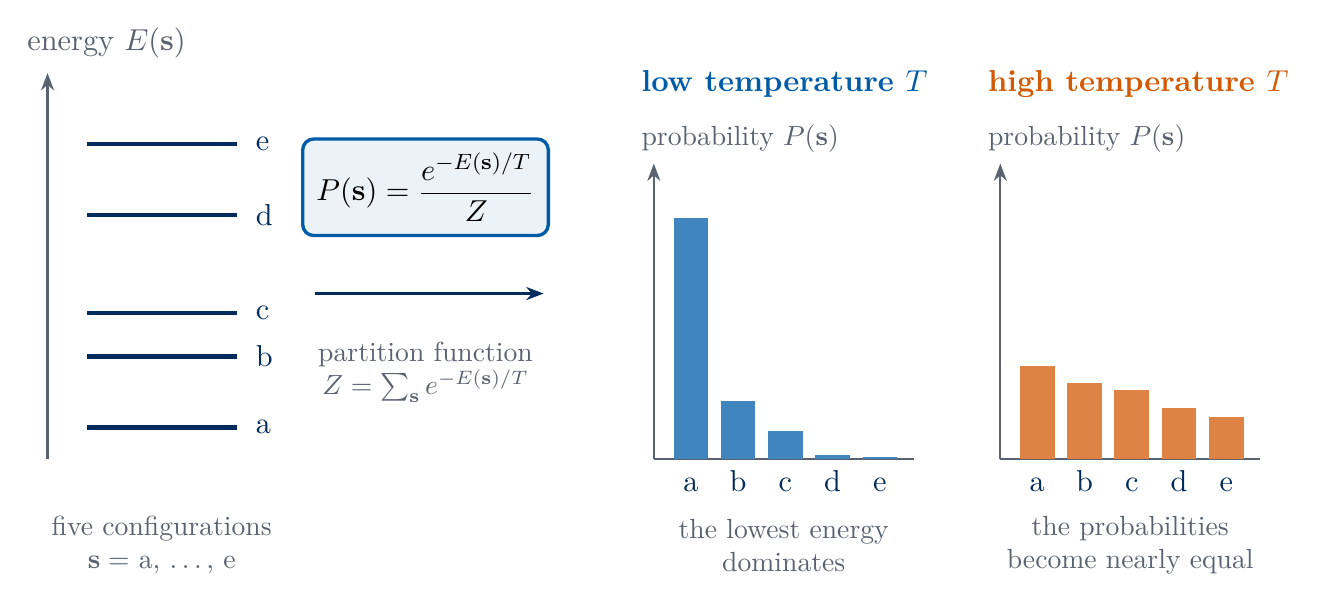

The sketch illustrates equation (2) for five configurations, labelled a to e in the order of their energy, which it denotes by $E$. At low temperature the configuration of lowest energy takes almost all the probability, and at high temperature the probabilities become nearly equal.

On the infinite lattice the model orders below the critical temperature $T_c=2/\ln(1+\sqrt2)\approx2.269$ [5]. Below $T_c$ most spins point in the same direction, and above $T_c$ domains of both directions coexist. We describe a configuration by its magnetisation per spin and its energy per spin,
$$m(\mathbf s)=\frac1N\sum_{i=1}^Ns_i,\qquad e(\mathbf s)=\frac{H(\mathbf s)}N . \tag{3}$$

We produce the data with the Metropolis algorithm [6], for a lattice with $L=10$ at the two temperatures $T=2.0\approx0.88\,T_c$ and $T=3.0\approx1.32\,T_c$. A sweep proposes a flip of every spin once and accepts it with the probability $\min(1,e^{-\Delta H/T})$, where $\Delta H$ is the change of the energy (1). The sequence of configurations produced in this way is a Markov chain, a random sequence in which each configuration is drawn using only the configuration before it. A distribution that one step of the chain leaves unchanged is called a stationary distribution of the chain. The acceptance rule makes the Gibbs distribution (2) stationary, so after many sweeps the configurations are distributed according to it. We update the two sublattices of the checkerboard in turn, because the spins of one sublattice share no bond and can be updated together. We run 2000 independent chains. Each chain starts from an ordered lattice with a random overall sign and discards 200 sweeps, which lets it forget the ordered start. It then contributes five configurations that are 25 sweeps apart. The spacing reduces the correlation between successive configurations of one chain, and the five configurations of a chain remain partly correlated. This gives 10 000 configurations per temperature.

The symmetry of equation (1) under a flip of all spins requires both signs of the magnetisation to be equally probable. At $T=2.0$ a chain of this length rarely changes its sign, as the printed count below shows, so the balance of the two signs in our data comes from the random initial sign. The same slow exchange between the two signs returns in Section 7, where it limits the RBM.

The units of an RBM take the values 0 and 1. We map a spin to a unit by $s_i=1-2v_i$, so the unit value $v_i=0$ stands for $s_i=+1$ and $v_i=1$ for $s_i=-1$. 

The next cell defines the sampler and the conversions. The array `s` of the function `metropolis` has shape `(chains, L, L)`, so all chains are updated together by array operations. The function returns all stored configurations in one array of shape `(D, L, L)` with $D=10\,000$.

In [3]:
L = 10; N = L * L                                            # lattice size and number of spins
T_C = 2 / np.log(1 + np.sqrt(2))                             # critical temperature of the infinite lattice
T_LOW, T_HIGH = 2.0, 3.0
N_CHAINS_MC, SWEEPS_EQUIL, N_KEEP, SWEEPS_BETWEEN = 2000, 200, 5, 25

def metropolis(T, rng, n_chains=N_CHAINS_MC, n_equil=SWEEPS_EQUIL, n_keep=N_KEEP, n_between=SWEEPS_BETWEEN):
    # Start: all spins +1, multiplied by one random sign per chain. The random signs have shape (chains, 1, 1),
    # and broadcasting repeats them over the lattice directions.
    # np.float32 stores numbers in single precision, which saves memory and time for these many chains.
    s = np.ones((n_chains, L, L), np.float32) * rng.choice(np.array([-1, 1], np.float32), (n_chains, 1, 1))
    row, col = np.indices((L, L))                            # row and column index of every site, each of shape (L, L)
    sublattices = [(row + col) % 2 == c for c in (0, 1)]     # boolean masks of the two checkerboard sublattices
    kept = []
    for sweep in range(n_equil + (n_keep - 1) * n_between + 1):
        for sub in sublattices:
            # np.roll shifts a lattice by one site with periodic wrap-around, so these four terms are the neighbours
            neighbours = np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2)
            delta_H = 2 * s * neighbours                     # change of equation (1) if the spin is flipped
            # min(1, exp(-dH/T)): a uniform random number below exp(-dH/T) accepts, which is automatic for dH <= 0
            accept = rng.random(s.shape, dtype=np.float32) < np.exp(-delta_H / T)
            s = np.where(sub & accept, -s, s)                # flip only accepted spins of this sublattice
        if sweep >= n_equil and (sweep - n_equil) % n_between == 0:
            kept.append(s.copy())
    return np.concatenate(kept).astype(np.float64)           # first all chains at the first kept sweep, and so on

def magnetisation(s):
    return s.reshape(len(s), -1).mean(1)                     # m of equation (3), one value per configuration

def energy_per_spin(s):
    s = s.reshape(len(s), L, L)
    # the neighbour to the right and the neighbour below count every bond once
    return -(s * np.roll(s, 1, 1) + s * np.roll(s, 1, 2)).mean((1, 2))

def to_units(s):
    return ((1 - s) / 2).reshape(len(s), -1)                 # spin +1 -> unit 0, spin -1 -> unit 1, shape (D, N)

def to_spins(v):
    return 1 - 2 * np.asarray(v, np.float64)                 # the inverse map, s = 1 - 2 v

def sample_data(T, seed=79):
    # a generator seeded with two numbers: the same seed gives each temperature its own reproducible random sequence
    return metropolis(T, np.random.default_rng([seed, int(round(100 * T))]))

The next cell generates the two data sets and evaluates the magnetisation and the energy (3) of every configuration. The dictionary `SPINS` holds the configurations and `DATA_OBS` the two observables, each an array of shape `(D,)`. The count of sign changes compares, for every Monte Carlo chain, the first and the last stored configuration.

T = 2.0 = 0.88 T_c: 10000 configurations, <|m|> = 0.911, <e> = -1.746, fraction with m > 0: 0.50; chains whose sign differs between first and last stored sweep: 21 of 2000
T = 3.0 = 1.32 T_c: 10000 configurations, <|m|> = 0.275, <e> = -0.824, fraction with m > 0: 0.49; chains whose sign differs between first and last stored sweep: 969 of 2000
critical temperature of the infinite lattice T_c = 2.2692; Metropolis sampling took 6.9 s


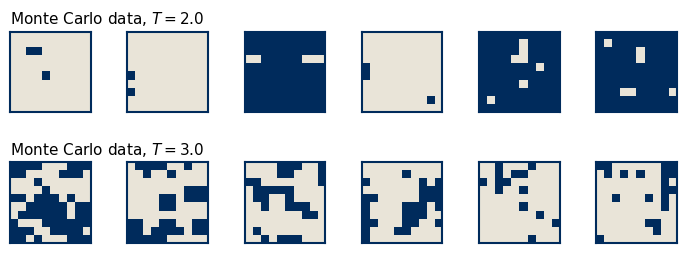

In [4]:
t0 = time.perf_counter()
SPINS, DATA_OBS = {}, {}
sign_changes_mc = {}
for T in (T_LOW, T_HIGH):
    SPINS[T] = sample_data(T)
    m, e = magnetisation(SPINS[T]), energy_per_spin(SPINS[T])
    DATA_OBS[T] = dict(m=m, e=e)
    # m has shape (D,). Reshaped to (N_KEEP, chains), row 0 is the first and row -1 the last stored sweep of every chain.
    m_by_chain = m.reshape(N_KEEP, N_CHAINS_MC)
    sign_changes_mc[T] = int(np.sum(m_by_chain[0] * m_by_chain[-1] < 0))
    print(f"T = {T} = {T / T_C:.2f} T_c: {len(SPINS[T])} configurations, <|m|> = {np.abs(m).mean():.3f}, <e> = {e.mean():.3f},"
          f" fraction with m > 0: {np.mean(m > 0):.2f}; chains whose sign differs between first and last stored sweep: {sign_changes_mc[T]} of {N_CHAINS_MC}")
print(f"critical temperature of the infinite lattice T_c = {T_C:.4f}; Metropolis sampling took {time.perf_counter() - t0:.1f} s")
plot_ising_data(SPINS[T_LOW][:6], SPINS[T_HIGH][:6])

Each row shows six of the 10 000 Monte Carlo configurations, with navy squares for $s_i=+1$ and light squares for $s_i=-1$. At $T=2.0$ almost all spins of a configuration agree, with $\langle|m|\rangle\approx0.91$, and one half of the configurations has $m>0$, so the distribution of $m$ has two separate peaks near $\pm1$. Only 21 of the 2000 chains at this temperature have different signs at their first and last stored sweep, against 969 at $T=3.0$. At $T=3.0$ every configuration contains domains of both directions and $\langle|m|\rangle\approx0.28$. The mean energies per spin are $-1.75$ and $-0.82$. A model of the data at $T=2.0$ has to represent two groups of configurations that differ in almost every spin. Lab 078 drew the spin $+1$ of its digit images in white, whereas navy marks $+1$ in this notebook.

### A chain with two states

A chain can need many steps to reach its stationary distribution even when this distribution is correct, as a chain with two states shows. Let the states be the two signs of the magnetisation. In one step the chain goes from $+$ to $-$ with the probability $a$ and from $-$ to $+$ with the probability $b$. The transition matrix $Q$, with rows for the present and columns for the next state, and its stationary distribution $\boldsymbol\pi$ are
$$Q=\begin{pmatrix}1-a&a\\b&1-b\end{pmatrix},\qquad \boldsymbol\pi\,Q=\boldsymbol\pi,\qquad \boldsymbol\pi=\frac{(b,\;a)}{a+b} .$$
The distribution after $t$ steps is the starting row vector multiplied by $Q^t$, and it approaches $\boldsymbol\pi$ with the factor $(1-a-b)^t$. For small $a$ and $b$ this takes about $1/(a+b)$ steps, however correct the stationary distribution is. The next cell evaluates this for $a=0.01$ and $b=0.02$, starting in the state $+$. Section 7 meets the same situation in the chains of the trained machine.

In [5]:
a_two, b_two = 0.01, 0.02
T_two = np.array([[1 - a_two, a_two], [b_two, 1 - b_two]])   # transition matrix, shape (2, 2)
pi_two = np.array([b_two, a_two]) / (a_two + b_two)          # stationary distribution
start_two = np.array([1.0, 0.0])                             # the chain starts in the state +
print("stationary distribution", pi_two.round(3), "  unchanged by one step:", np.allclose(pi_two @ T_two, pi_two))
for t in (1, 10, 33, 100, 300):
    print(f"after {t:3d} steps: P(+) = {(start_two @ np.linalg.matrix_power(T_two, t))[0]:.3f}")

stationary distribution [0.667 0.333]   unchanged by one step: True
after   1 steps: P(+) = 0.990
after  10 steps: P(+) = 0.912
after  33 steps: P(+) = 0.789
after 100 steps: P(+) = 0.683
after 300 steps: P(+) = 0.667


## 3. The restricted Boltzmann machine and its conditional probabilities

### Stochastic units

In the Hopfield network of Lab 078 a spin $s_i=\pm1$ feels the local field $\phi_i=\sum_jJ_{ij}s_j$ and takes the value $\mathrm{sign}(\phi_i)$. The two values of the spin have the energies $\mp\phi_i$. A Boltzmann machine replaces the deterministic rule by a thermal one. At inverse temperature $\beta$ the spin takes each value with the probability given by its Boltzmann factor,
$$P(s_i=+1)=\frac{e^{\beta\phi_i}}{e^{\beta\phi_i}+e^{-\beta\phi_i}}=\sigma(2\beta\phi_i),\qquad \sigma(x)=\frac1{1+e^{-x}} . \tag{3a}$$
The function $\sigma$ is the logistic function, or sigmoid. For $\beta\to\infty$ the probability becomes one for $\phi_i>0$ and zero for $\phi_i<0$, which is the sign rule, so the Hopfield update is the zero-temperature limit of this stochastic update.

The units of an RBM take the values 0 and 1, which is the usual convention for this model. A unit $v\in\{0,1\}$ with the energy $-v\chi$ has the two energies $0$ and $-\chi$, so
$$P(v=1)=\frac{e^{\chi}}{1+e^{\chi}}=\sigma(\chi) . \tag{3b}$$
The input $\chi$ plays the role of the local field. The factor 2 of equation (3a) has disappeared because the two values of a spin differ by 2, whereas those of a unit differ by 1. With our map $s=1-2v$ the spin energy reads $-s\phi=2v\phi-\phi$, so the two descriptions agree for $\chi=-2\beta\phi$, and the temperature is absorbed into the parameters. Such a linear change of variables also turns an energy written with spins into an energy of the same form written with units, with shifted biases, so both encodings describe the same family of distributions. They differ in the training that we apply later, as Section 9 shows.

The next cell evaluates equation (3a) for three values of $\beta$. Its input is an array of field values and its output a table with one column per $\beta$.

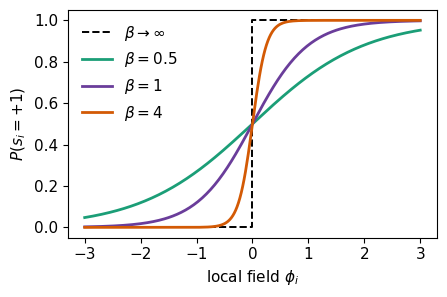

In [6]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))                              # sigma(x) of equation (3a), applied entry by entry

phi_values = np.linspace(-3, 3, 241)
BETAS = (0.5, 1, 4)
# one curve per beta: the probability of s = +1, equation (3a)
curves = [sigmoid(2 * beta * phi_values) for beta in BETAS]
plot_stochastic_unit(phi_values, BETAS, curves)

The figure shows the probability of $s_i=+1$ against the local field. With growing $\beta$ the sigmoid approaches the dashed step, the sign rule of the Hopfield network.

### Energy of the machine

An energy-based model assigns an energy to every configuration and turns it into a probability with the Gibbs distribution, as in equation (2), with the temperature absorbed into the parameters. A Boltzmann machine [2] is such a model made of binary units with pairwise couplings. Some of its units are visible and hold the data, and the others are hidden, which means that they belong to the model and are never observed. The restricted Boltzmann machine keeps only the connections between a visible and a hidden unit.

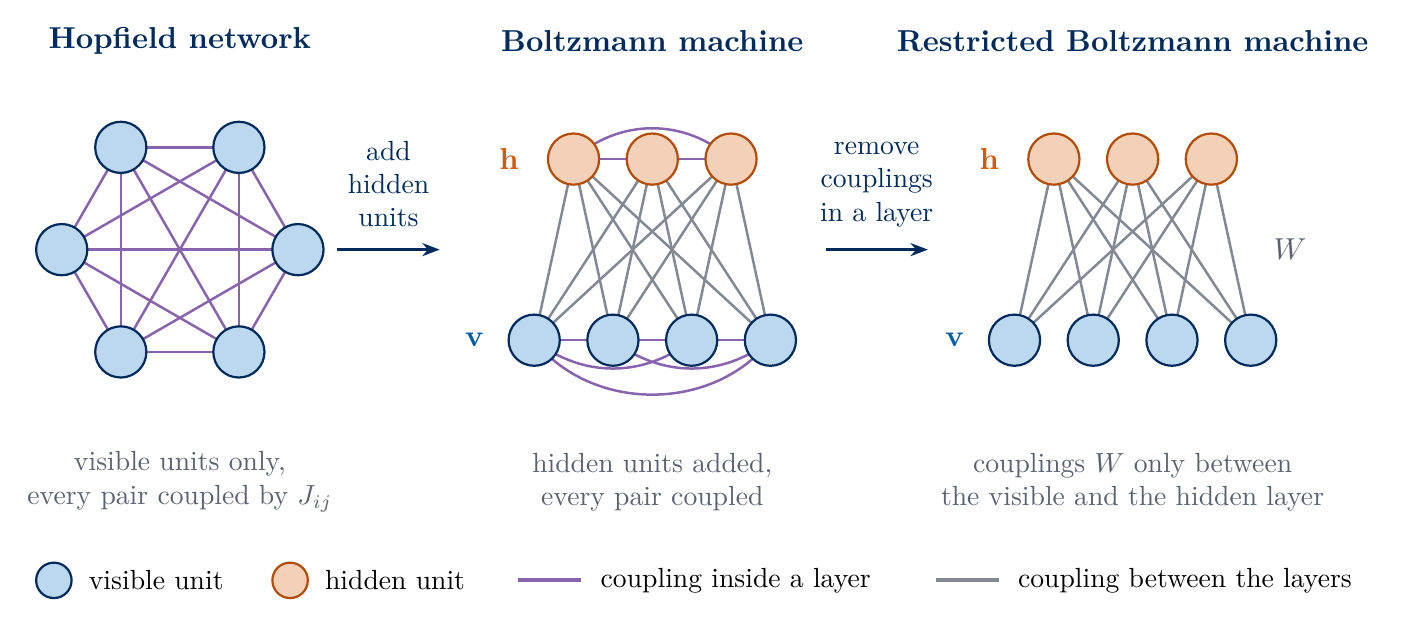

The sketch shows three networks. The Hopfield network has visible units only, with every pair coupled. The Boltzmann machine adds hidden units, and the restricted Boltzmann machine removes the couplings inside each layer.

With visible units $v_i\in\{0,1\}$, $i=1,\dots,N$, and hidden units $h_j\in\{0,1\}$, $j=1,\dots,M$, the energy of the RBM is
$$E(\mathbf v,\mathbf h)=-\mathbf a\cdot\mathbf v-\mathbf c\cdot\mathbf h-\mathbf v^{\top}W\mathbf h=-\sum_ia_iv_i-\sum_jc_jh_j-\sum_{i,j}v_iW_{ij}h_j , \tag{4}$$
with visible biases $a_i$, hidden biases $c_j$ and an $N\times M$ matrix of weights $W_{ij}$, which are the learned parameters. The joint distribution and the distribution of the visible units are
$$p(\mathbf v,\mathbf h)=\frac{e^{-E(\mathbf v,\mathbf h)}}Z,\qquad p(\mathbf v)=\sum_{\mathbf h}p(\mathbf v,\mathbf h),\qquad Z=\sum_{\mathbf v,\mathbf h}e^{-E(\mathbf v,\mathbf h)} . \tag{5}$$
The distribution $p(\mathbf v)$ is the model of the data.

Without connections inside a layer, the energy (4) is a sum of terms that each contain a single hidden unit, $E=-\mathbf a\cdot\mathbf v-\sum_jh_j\chi_j$, where $\chi_j=c_j+\sum_iv_iW_{ij}$ is the input that hidden unit $j$ receives from the visible layer. This input is the local field of the hidden unit in the sense of equation (3b). For fixed visible units the conditional distribution of the hidden layer is $p(\mathbf v,\mathbf h)$ divided by its sum over $\mathbf h$. The factor $e^{\mathbf a\cdot\mathbf v}/Z$ cancels and the rest is a product,
$$P(\mathbf h|\mathbf v)=\frac{\prod_je^{h_j\chi_j}}{\sum_{\mathbf h'}\prod_je^{h'_j\chi_j}}=\prod_j\frac{e^{h_j\chi_j}}{1+e^{\chi_j}} , \tag{6}$$
because the sum over all hidden configurations factorises into the sums over $h'_j\in\{0,1\}$ of every unit. Given the visible layer the hidden units are therefore independent, and each is switched on with the probability
$$P(h_j=1|\mathbf v)=\frac{e^{\chi_j}}{1+e^{\chi_j}}=\sigma\Big(c_j+\sum_iv_iW_{ij}\Big) . \tag{7}$$
The energy has the same form in both layers, so the same argument gives
$$P(v_i=1|\mathbf h)=\sigma\Big(a_i+\sum_jW_{ij}h_j\Big) . \tag{8}$$
A whole layer is thus sampled in one step from the other layer, with one matrix product and one random number per unit.

We check equations (6) to (8) on a machine with four visible and three hidden units and random parameters drawn from a normal distribution of unit width. We list all $2^7=128$ joint configurations, compute their probabilities from equations (4) and (5), and obtain the conditional probabilities by summing entries of this table. The next cell does this. The table `P_joint` has shape `(16, 8)`, with rows for the visible and columns for the hidden configurations. Dividing it by the sum of each row gives $P(\mathbf h|\mathbf v)$, and dividing it by the sum of each column gives $P(\mathbf v|\mathbf h)$. The figure compares the conditional probabilities with the sigmoid formulas (7) and (8).

largest deviation of P(h_j=1|v) from equation (7): 2.2e-16
largest deviation of P(v_i=1|h) from equation (8): 2.2e-16
largest deviation of P(h|v) from the product of its factors: 1.7e-16


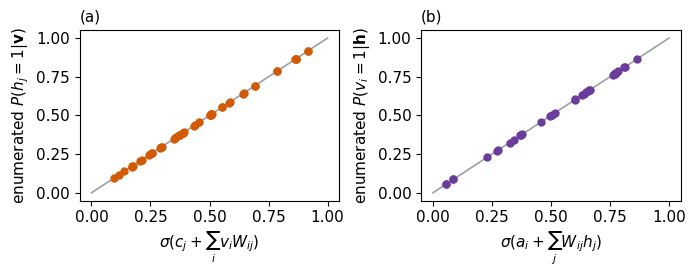

In [7]:
def all_bits(n):
    # All 2^n bit strings of length n as an array of shape (2^n, n), with unit 0 as the most significant bit.
    k = np.arange(2 ** n)[:, None]                           # the numbers 0, ..., 2^n - 1 as a column
    # >> shifts the bits to the right; & 1 keeps the lowest one. Broadcasting does this for every number and position.
    return ((k >> np.arange(n)[::-1]) & 1).astype(np.float64)

NV_TINY, NH_TINY = 4, 3
all_v, all_h = all_bits(NV_TINY), all_bits(NH_TINY)          # shapes (16, 4) and (8, 3)

def joint_distribution(a, c, W):
    # Table of p(v, h), equations (4) and (5). Every term of the exponent has shape (16, 8):
    # a . v depends only on the row and is repeated along the columns, c . h only on the column, v^T W h on both.
    exponent = (all_v @ a)[:, None] + (all_h @ c)[None, :] + all_v @ W @ all_h.T
    P = np.exp(exponent)
    return P / P.sum()

rng_tiny = np.random.default_rng(79)
a_t, c_t, W_t = rng_tiny.normal(0, 1, NV_TINY), rng_tiny.normal(0, 1, NH_TINY), rng_tiny.normal(0, 1, (NV_TINY, NH_TINY))
P_joint = joint_distribution(a_t, c_t, W_t)                  # all 2^7 joint probabilities, shape (16, 8)

# conditionals from the table; keepdims=True keeps the summed axis, so that the division broadcasts correctly
P_h_given_v = P_joint / P_joint.sum(1, keepdims=True)        # each row sums to one
enum_h = P_h_given_v @ all_h                                 # P(h_j = 1 | v), shape (16, 3)
form_h = sigmoid(c_t + all_v @ W_t)                          # equation (7), shape (16, 3)
P_v_given_h = P_joint / P_joint.sum(0, keepdims=True)        # each column sums to one
enum_v = all_v.T @ P_v_given_h                               # P(v_i = 1 | h), shape (4, 8)
form_v = sigmoid(a_t[:, None] + W_t @ all_h.T)               # equation (8), shape (4, 8)

# Equation (6): P(h | v) is the product over j of sigma(chi_j) for h_j = 1 and of 1 - sigma(chi_j) for h_j = 0.
h_is_one = all_h[None] == 1                                  # shape (1, 8, 3): hidden configuration, unit
p_one = form_h[:, None, :]                                   # shape (16, 1, 3): visible configuration, unit
factors = np.where(h_is_one, p_one, 1 - p_one)               # broadcasting gives shape (16, 8, 3)
product = np.prod(factors, axis=2)                           # product over the units, shape (16, 8)

dev_h, dev_v, dev_prod = np.abs(enum_h - form_h).max(), np.abs(enum_v - form_v).max(), np.abs(product - P_h_given_v).max()
print(f"largest deviation of P(h_j=1|v) from equation (7): {dev_h:.1e}")
print(f"largest deviation of P(v_i=1|h) from equation (8): {dev_v:.1e}")
print(f"largest deviation of P(h|v) from the product of its factors: {dev_prod:.1e}")
assert max(dev_h, dev_v, dev_prod) < 1e-12
plot_conditionals(form_h, enum_h, form_v, enum_v)

Every point is one conditional probability of one unit, computed from the table of the 128 joint probabilities on the vertical axis and from the sigmoid formula on the horizontal axis. Panel (a) contains the 48 values of $P(h_j=1|\mathbf v)$ and panel (b) the 32 values of $P(v_i=1|\mathbf h)$. All points lie on the diagonal, and the printed deviations are of order $10^{-16}$, the size of rounding errors. The product form (6) holds to the same accuracy.

### Hidden units

The hidden units allow the visible units to be correlated, although the energy (4) contains no coupling between two visible units. The sum over $\mathbf h$ in equation (5) factorises in the same way as in equation (6), and the distribution of the visible units becomes
$$p(\mathbf v)=\frac{e^{-F(\mathbf v)}}Z,\qquad F(\mathbf v)=-\mathbf a\cdot\mathbf v-\sum_{j=1}^M\ln\big(1+e^{\chi_j(\mathbf v)}\big),\qquad \chi_j(\mathbf v)=c_j+\sum_iv_iW_{ij} . \tag{8a}$$
The quantity $F(\mathbf v)$ is called the free energy of the visible configuration $\mathbf v$, obtained by summing out the hidden layer, and it acts as the energy of the visible units alone. Each hidden unit adds one term $\ln(1+e^{\chi_j})$ that depends on a weighted sum of all the visible units to which it is connected, and this nonlinear function of a sum couples these units to each other.

For two visible units connected to one hidden unit we write $w_1,w_2$ for the two weights and $\gamma$ for the bias of this unit, all single numbers. Any function of $v_1,v_2\in\{0,1\}$ can be written as $A+B_1v_1+B_2v_2+Kv_1v_2$. For $g(v_1,v_2)=\ln\big(1+e^{\gamma+w_1v_1+w_2v_2}\big)$ the coefficient of the product is
$$K=g(1,1)+g(0,0)-g(1,0)-g(0,1) . \tag{8b}$$
The hidden unit thus produces an effective coupling $K$ between the two visible units. For $w_1$ and $w_2$ of equal sign the convexity of $\ln(1+e^x)$ makes $K$ positive, which favours $v_1=v_2=1$, and together with the linear terms this can favour equal units, as the construction below shows. With more visible units the same function also generates terms with three and more visible units.

This mechanism can represent the Ising model without any approximation. The energy (1) has one coupling per bond, and we give every bond its own hidden unit, connected to the two sites of the bond with the same weight $w$ and with the bias $\gamma=-w$. Each of the two sites receives the additional bias $-w/2$. The contribution of the bond to $-F$ is then $g-\tfrac w2(v_1+v_2)$, with $g=\ln(1+e^{w(v_1+v_2-1)})$, and it takes the values

| $v_1+v_2$ | $s_1s_2$ | contribution to $-F$ |
|---|---|---|
| 0 | $+1$ | $\ln(1+e^{-w})$ |
| 1 | $-1$ | $\ln2-\tfrac w2$ |
| 2 | $+1$ | $\ln(1+e^{w})-w=\ln(1+e^{-w})$ |

The first and last rows agree. The difference between a satisfied and an unsatisfied bond is
$$\ln(1+e^{-w})-\ln2+\frac w2=\ln\frac{e^{w/2}+e^{-w/2}}{2}=\ln\cosh\frac w2 .$$
The Boltzmann factor $e^{Js_1s_2/T}$ has the same ratio if $\ln\cosh(w/2)=2J/T$, which means
$$\cosh\frac w2=e^{2J/T} . \tag{8c}$$
On our lattice with $N=100$ sites there are $2N=200$ bonds, so $M=200$ hidden units with two nonzero weights each reproduce the Gibbs distribution (2) for every configuration, and every site, which belongs to four bonds, has the bias $a_i=-2w$. A machine with fewer hidden units cannot use this construction, and training has to find a compressed description whose marginal $p(\mathbf v)$ approximates the Gibbs distribution. We use $M=64$ hidden units in Section 6, which is well below 200, and Section 9 varies this number.

The next cell defines `free_energy`, which implements equation (8a) for an array of visible configurations of shape `(D, N)` and returns an array of shape `(D,)`. The NumPy function `np.logaddexp(0, x)` computes $\ln(1+e^x)$ without overflow for large $x$. The cell then builds the exact machine at $T=2.0$ and checks on random configurations that $F(\mathbf v)-H(\mathbf s)/T$ does not depend on the configuration, which is the statement that $p(\mathbf v)$ equals the Gibbs distribution.

In [8]:
def free_energy(params, v):
    a, c, W = params                                         # a has shape (N,), c shape (M,), W shape (N, M)
    chi = c + v @ W                                          # chi_j for every configuration, shape (D, M)
    return -(v @ a) - np.logaddexp(0, chi).sum(1)            # equation (8a), shape (D,)

def lattice_bonds():
    # The 2 N bonds of the periodic lattice. Site (row, col) has the index row * L + col, as in s.reshape(L, L).
    bonds = []
    for row in range(L):
        for col in range(L):
            site = row * L + col
            bonds.append((site, row * L + (col + 1) % L))    # bond to the right neighbour
            bonds.append((site, ((row + 1) % L) * L + col))  # bond to the neighbour below
    return bonds

def exact_ising_rbm(T):
    W_bond = 2 * np.arccosh(np.exp(2 / T))                   # equation (8c) with J = 1
    bonds = lattice_bonds()
    W = np.zeros((N, len(bonds)))                            # one column per hidden unit, shape (N, 200)
    for j, (site_1, site_2) in enumerate(bonds):
        W[site_1, j] = W[site_2, j] = W_bond
    c = -W_bond * np.ones(len(bonds))
    a = -2 * W_bond * np.ones(N)                             # every site belongs to four bonds, each contributing -W/2
    return (a, c, W), W_bond

exact_params, W_bond = exact_ising_rbm(T_LOW)
test_spins = np.random.default_rng(7902).choice([-1.0, 1.0], size=(200, N))   # random configurations, shape (200, N)
ising_over_T = N * energy_per_spin(test_spins) / T_LOW       # H(s) / T for every configuration
difference = free_energy(exact_params, to_units(test_spins)) - ising_over_T
exact_spread = float(difference.max() - difference.min())
print(f"bond weight W = {W_bond:.3f} at T = {T_LOW}, hidden units M = {exact_params[2].shape[1]}")
print(f"F(v) - H(s)/T over 200 random configurations: spread {exact_spread:.1e} (constant up to rounding errors)")

bond weight W = 3.315 at T = 2.0, hidden units M = 200
F(v) - H(s)/T over 200 random configurations: spread 2.0e-13 (constant up to rounding errors)


## 4. The gradient of the log-likelihood

Learning chooses the parameters that make the data most probable. For $D$ observed configurations $\mathbf v_1,\dots,\mathbf v_D$ the log-likelihood per configuration, measured in nats because the logarithm is natural, is
$$\ell(\theta)=\frac1D\sum_{d=1}^D\ln p\big(\mathbf v_d\big)=\Big\langle\ln\sum_{\mathbf h}e^{-E(\mathbf v,\mathbf h)}\Big\rangle_{\rm data}-\ln Z , \tag{9}$$
where $\theta$ stands for any of the parameters $a_i$, $c_j$, $W_{ij}$ and $\langle\cdot\rangle_{\rm data}$ is the average over the $D$ configurations. Both terms are logarithms of sums of Boltzmann factors. Differentiating such a logarithm gives
$$\frac{\partial}{\partial\theta}\ln\sum_{\mathbf h}e^{-E}=\frac{\sum_{\mathbf h}e^{-E}\,(-\partial E/\partial\theta)}{\sum_{\mathbf h'}e^{-E}} ,$$
and the ratio $e^{-E(\mathbf v,\mathbf h)}/\sum_{\mathbf h'}e^{-E(\mathbf v,\mathbf h')}$ is the conditional probability $P(\mathbf h|\mathbf v)$. The derivative is therefore an average of $-\partial E/\partial\theta$ with these normalised Boltzmann factors as weights, and the same steps apply to $\ln Z$,
$$\frac{\partial}{\partial\theta}\ln\sum_{\mathbf h}e^{-E(\mathbf v,\mathbf h)}=-\sum_{\mathbf h}P(\mathbf h|\mathbf v)\frac{\partial E}{\partial\theta},\qquad \frac{\partial\ln Z}{\partial\theta}=-\sum_{\mathbf v,\mathbf h}p(\mathbf v,\mathbf h)\frac{\partial E}{\partial\theta} . \tag{10}$$
In the first expression the visible units are fixed by the data and only the hidden units are averaged. In the second expression both layers are drawn from the model. The gradient therefore consists of two averages of the same quantity,
$$\frac{\partial\ell}{\partial\theta}=\underbrace{-\Big\langle\sum_{\mathbf h}P(\mathbf h|\mathbf v)\frac{\partial E}{\partial\theta}\Big\rangle_{\rm data}}_{\text{positive phase}}+\underbrace{\Big\langle\frac{\partial E}{\partial\theta}\Big\rangle_{\rm model}}_{\text{negative phase}} . \tag{11}$$
A step along the positive phase lowers the energy of the configurations in the data. A step along the negative phase raises the energy of the configurations that the model currently produces. The Hebbian rule of the Hopfield network, which builds the couplings from the stored patterns alone, contains only the first of these two changes, and the second raises the energy of configurations that the model produces without support from the data [1].

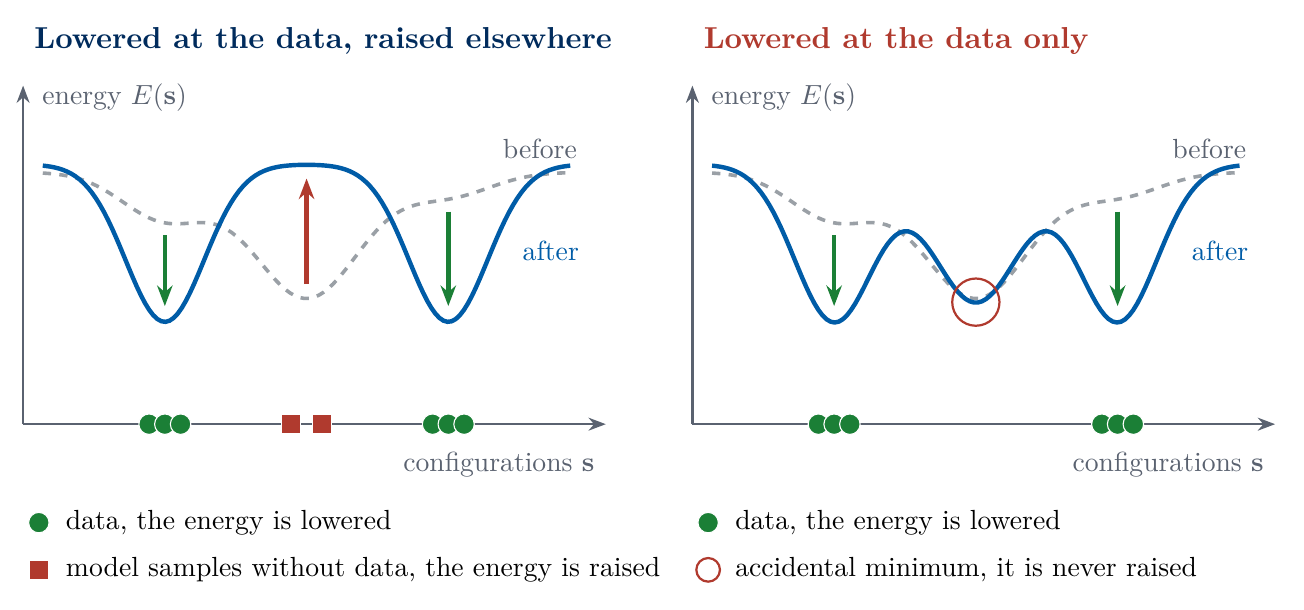

The sketch shows both cases. With the two phases the energy is lowered at the data and raised at configurations that the model produces without data. With the positive phase alone a minimum that formed away from the data is never raised.

For the energy (4) the derivatives are $\partial E/\partial W_{ij}=-v_ih_j$, $\partial E/\partial a_i=-v_i$ and $\partial E/\partial c_j=-h_j$. The average of $h_j$ over $P(\mathbf h|\mathbf v)$ is the probability (7), so
$$\frac{\partial\ell}{\partial W_{ij}}=\big\langle v_i\,P(h_j=1|\mathbf v)\big\rangle_{\rm data}-\big\langle v_ih_j\big\rangle_{\rm model},\qquad
\frac{\partial\ell}{\partial a_i}=\langle v_i\rangle_{\rm data}-\langle v_i\rangle_{\rm model},\qquad
\frac{\partial\ell}{\partial c_j}=\big\langle P(h_j=1|\mathbf v)\big\rangle_{\rm data}-\langle h_j\rangle_{\rm model} . \tag{12}$$
The model averages can also be written with the probability (7), $\langle v_ih_j\rangle_{\rm model}=\langle v_iP(h_j=1|\mathbf v)\rangle_{\rm model}$, where $\mathbf v$ is drawn from $p(\mathbf v)$. A weight grows as long as a visible and a hidden unit are switched on together more often when the visible layer holds the data than when the model runs freely. We climb the log-likelihood by gradient ascent with a step size $\eta$,
$$\theta\leftarrow\theta+\eta\,\frac{\partial\ell}{\partial\theta} , \tag{13}$$
and learning stops when the two phases are equal.

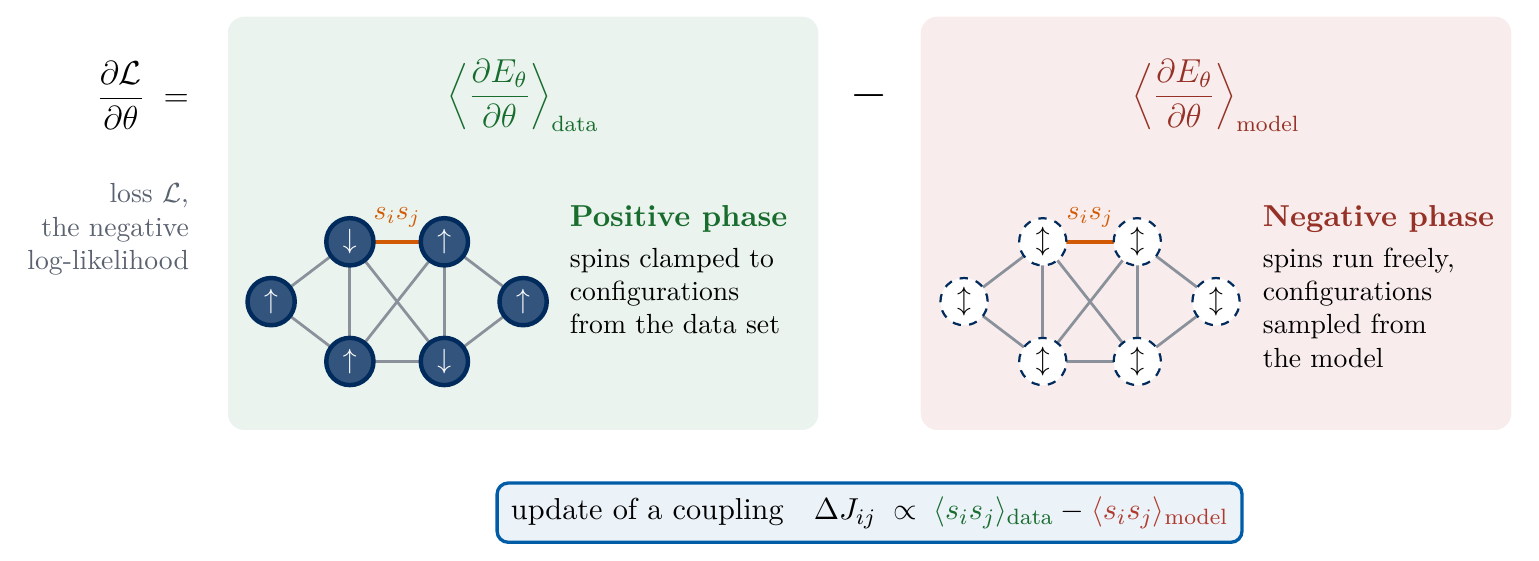

The sketch shows the two phases for a general Boltzmann machine with spins $s_i$ and couplings $J_{ij}$, in which all units are visible. In the positive phase the spins are clamped, which means held fixed, at configurations of the data, and in the negative phase they are sampled from the model. In the RBM only the visible units are clamped, and the hidden units are averaged with $P(\mathbf h|\mathbf v)$ as in equation (12). The sketch is written for the loss $\mathcal L=-\ell$, so its gradient is the data average minus the model average of $\partial E/\partial\theta$, the negative of equation (11).

For the small machine both phases are sums over at most 128 terms, so the gradient can be evaluated without sampling. As data we take the $2\times2$ patch of neighbouring spins in one corner of every Monte Carlo configuration at $T=2.0$, which gives the frequencies of the 16 configurations of four units. We first compare equation (12), at the random parameters of Section 3, with the derivative of equation (9) obtained from central finite differences. We then train the machine with the update (13) for 3000 steps with $\eta=0.5$, starting from zero biases and small random weights, and record the two phases of the weight $W_{11}$ together with the log-likelihood. Panel (a) of the figure shows the comparison of the gradients and panel (b) the two phases during training.

Two quantities measure how well the small machine fits. The entropy of the data is $S_{\rm data}=-\sum_{\mathbf v}p_{\rm data}(\mathbf v)\ln p_{\rm data}(\mathbf v)$, where $p_{\rm data}(\mathbf v)$ is the frequency of the configuration $\mathbf v$ in the data. The Kullback–Leibler divergence from the data to the model is
$$D_{\rm KL}=\sum_{\mathbf v}p_{\rm data}(\mathbf v)\ln\frac{p_{\rm data}(\mathbf v)}{p(\mathbf v)}=-S_{\rm data}-\ell . \tag{13a}$$
It is never negative and vanishes only when the two distributions agree, so the log-likelihood is at most $-S_{\rm data}$, and raising $\ell$ lowers $D_{\rm KL}$ by the same amount.

The next cell prepares the data of the small machine and defines the exact log-likelihood and the two phases. The vector `p_data` of shape `(16,)` holds the frequency of each visible configuration in the data. The function `two_phases` returns each phase as a dictionary with the keys `"a"`, `"c"` and `"W"`, whose entries have the shapes `(4,)`, `(3,)` and `(4, 3)`.

In [9]:
# Data of the small machine: the patch of 2 x 2 neighbouring spins in the corner of every configuration at T = 2.0.
patch = to_units(SPINS[T_LOW][:, :2, :2])                    # shape (D, 4); [:, :2, :2] keeps rows and columns 0 and 1
index = (patch @ 2 ** np.arange(NV_TINY)[::-1]).astype(int)  # reads the four bits as a number from 0 to 15
p_data = np.bincount(index, minlength=2 ** NV_TINY) / len(patch)   # frequency of each of the 16 configurations
entropy_data = -np.sum(p_data[p_data > 0] * np.log(p_data[p_data > 0]))   # S_data; the mask avoids log(0)

def log_likelihood(a, c, W):
    p_visible = joint_distribution(a, c, W).sum(1)           # p(v) of equation (5), shape (16,)
    return p_data @ np.log(p_visible)                        # equation (9), written as a sum over the 16 configurations

def phase(p_v, ph):
    # Average of v_i, of P(h_j=1|v) and of v_i P(h_j=1|v) over the visible distribution p_v, shape (16,).
    # p_v[:, None] has shape (16, 1), so v_weighted has shape (16, 4) and holds p(v) v_i.
    v_weighted = all_v * p_v[:, None]
    # v_weighted.T has shape (4, 16) and ph has shape (16, 3), so the product has shape (4, 3).
    return dict(a=p_v @ all_v, c=p_v @ ph, W=v_weighted.T @ ph)

def two_phases(a, c, W, p_negative=None):
    # Positive and negative phase of equation (12).
    # p_negative replaces the exact model distribution of the visible units when it is given (Section 5).
    p_model = joint_distribution(a, c, W).sum(1) if p_negative is None else p_negative
    ph = sigmoid(c + all_v @ W)                              # P(h_j = 1 | v) for the 16 visible configurations, shape (16, 3)
    return phase(p_data, ph), phase(p_model, ph)

def flatten(parts):
    # all parameters in one vector of length 4 + 3 + 12 = 19, in the order a, c, W
    return np.concatenate([np.ravel(parts[name]) for name in ("a", "c", "W")])

def unflatten(theta):
    return theta[:NV_TINY], theta[NV_TINY:NV_TINY + NH_TINY], theta[NV_TINY + NH_TINY:].reshape(NV_TINY, NH_TINY)

We now compare equation (12) with a numerical derivative. Each of the 19 parameters is shifted by $\pm\varepsilon$ in turn, and the central difference of the log-likelihood (9) approximates its derivative. The rows of `np.eye(19)` are the unit vectors that select one parameter at a time.

In [10]:
positive, negative = two_phases(a_t, c_t, W_t)
grad_formula = flatten(positive) - flatten(negative)         # data average minus model average, equation (12)
theta_t, EPS = flatten(dict(a=a_t, c=c_t, W=W_t)), 1e-5
grad_numeric = np.array([(log_likelihood(*unflatten(theta_t + EPS * unit)) - log_likelihood(*unflatten(theta_t - EPS * unit))) / (2 * EPS)
                         for unit in np.eye(len(theta_t))])
dev_grad = np.abs(grad_formula - grad_numeric).max()
print(f"{len(theta_t)} parameters; largest gradient component {np.abs(grad_numeric).max():.3f},"
      f" largest deviation of equation (12) from the finite differences {dev_grad:.1e}")
assert dev_grad < 1e-8

19 parameters; largest gradient component 0.373, largest deviation of equation (12) from the finite differences 3.7e-11


The function `train_tiny` performs gradient ascent with the update (13). It starts from zero biases and small random weights, and it records in `trace` the log-likelihood and the two phases of the weight $W_{11}$ at every step. The argument `k`, with the default `None`, is used in Section 5, where the model average is replaced by the average after $k$ sampling steps. The divergence (13a) follows from the recorded log-likelihood.

log-likelihood per configuration: -2.775 -> -1.305 nats; its upper bound -S_data is -1.296 nats
D_KL(data || model): 1.479 -> 0.0087 nats after 3000 steps
weight W_11 (first visible and first hidden unit): data average 0.239 -> 0.055, model average 0.249 -> 0.055; smallest data average 0.016 at step 116


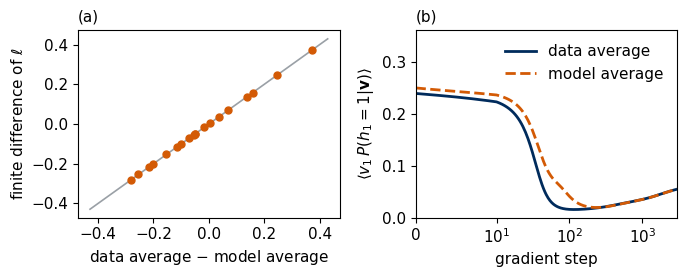

In [11]:
ETA_TINY, STEPS_TINY = 0.5, 3000

def train_tiny(k=None, seed=79):
    rng = np.random.default_rng(seed)
    a, c, W = np.zeros(NV_TINY), np.zeros(NH_TINY), 0.1 * rng.normal(0, 1, (NV_TINY, NH_TINY))
    trace = dict(ell=[], positive=[], negative=[])
    for step in range(STEPS_TINY + 1):
        p_negative = None if k is None else chain_distribution(a, c, W, k)   # chain_distribution is defined in Section 5
        positive, negative = two_phases(a, c, W, p_negative)
        trace["ell"].append(log_likelihood(a, c, W))
        trace["positive"].append(positive["W"][0, 0]); trace["negative"].append(negative["W"][0, 0])   # the two phases of W_11
        # equation (13) for each group of parameters
        a = a + ETA_TINY * (positive["a"] - negative["a"])
        c = c + ETA_TINY * (positive["c"] - negative["c"])
        W = W + ETA_TINY * (positive["W"] - negative["W"])
    return (a, c, W), {name: np.array(values) for name, values in trace.items()}

params_exact, trace_exact = train_tiny()
kl_exact = -entropy_data - trace_exact["ell"]                # D_KL of equation (13a) at every step, in nats
data_phase = trace_exact["positive"]
print(f"log-likelihood per configuration: {trace_exact['ell'][0]:.3f} -> {trace_exact['ell'][-1]:.3f} nats;"
      f" its upper bound -S_data is {-entropy_data:.3f} nats")
print(f"D_KL(data || model): {kl_exact[0]:.3f} -> {kl_exact[-1]:.4f} nats after {STEPS_TINY} steps")
print(f"weight W_11 (first visible and first hidden unit): data average {data_phase[0]:.3f} -> {data_phase[-1]:.3f},"
      f" model average {trace_exact['negative'][0]:.3f} -> {trace_exact['negative'][-1]:.3f};"
      f" smallest data average {data_phase.min():.3f} at step {int(np.argmin(data_phase))}")
plot_gradient(grad_formula, grad_numeric, trace_exact, STEPS_TINY)

Panel (a) compares the 19 components of the gradient. The horizontal axis is the difference of the data average and the model average from equation (12), and the vertical axis is the finite difference of the log-likelihood (9). The points lie on the diagonal with a largest deviation of $4\times10^{-11}$, which confirms the signs and the form of equation (12). Panel (b) shows the two phases of the weight $W_{11}$ during training. They start close together, at $0.239$ and $0.249$, and coincide after a few hundred steps, where the gradient of this weight vanishes. The data average also changes during training, although the data are fixed, because it contains $P(h_1=1|\mathbf v)$, which depends on the parameters. It starts at $0.239$, falls to $0.016$ at step 116 and settles at $0.055$.

The log-likelihood rises from $-2.775$ to $-1.305$ nats per configuration. Its largest possible value is minus the entropy of the data, $-1.296$ nats, reached when the model distribution equals the frequencies of the data. The difference between the two is the divergence $D_{\rm KL}$ of equation (13a), which falls from $1.48$ to $0.009$ nats and is still decreasing slowly at the end of the run.

## 5. Contrastive divergence

For 100 visible units the positive phase of equation (12) still costs one matrix product per configuration of the data, whereas the sum over the model would have $2^{100}$ terms for the visible units alone. The negative phase is therefore estimated from configurations sampled from the model. The conditionals of Section 3 provide a sampler that alternates between the layers, $\mathbf v\to\mathbf h\to\mathbf v'\to\dots$, where every arrow draws a whole layer from equation (7) or (8). One sampling step is the pair of moves from a visible configuration to the next one, and this procedure is called block Gibbs sampling. It applies the stochastic update (3b) to a whole layer at once, which is possible because the units of one layer are not coupled to each other. The same update of a single unit, the heat-bath rule, is also called Gibbs sampling. Each move draws a layer from its exact conditional distribution under $p(\mathbf v,\mathbf h)$, so a sample of the joint distribution stays a sample of it, and the model distribution $p(\mathbf v)$ is unchanged by a sampling step. All conditional probabilities are nonzero, and the standard convergence theorem for Markov chains then states that a chain started anywhere approaches $p(\mathbf v)$. The theorem gives no number of steps, and this number becomes the central difficulty of Section 7.

Contrastive divergence with $k$ steps (CD-$k$) [3] shortens this chain and starts it at the data. Each update uses a small subset of the training configurations, called a mini-batch, and consists of three operations.

1. Set the visible units to a training configuration $\mathbf v^{(0)}$ and compute $P(h_j=1|\mathbf v^{(0)})$.
2. Run $k$ alternating sampling steps from $\mathbf v^{(0)}$ and call the result $\mathbf v^{(k)}$.
3. Update the parameters with the step size $\eta$,
$$W_{ij}\leftarrow W_{ij}+\eta\Big(\overline{v^{(0)}_iP(h_j=1|\mathbf v^{(0)})}-\overline{v^{(k)}_iP(h_j=1|\mathbf v^{(k)})}\Big) , \tag{14}$$
and likewise $a_i\leftarrow a_i+\eta\,\overline{v^{(0)}_i-v^{(k)}_i}$ and $c_j\leftarrow c_j+\eta\,\overline{P(h_j=1|\mathbf v^{(0)})-P(h_j=1|\mathbf v^{(k)})}$, where the bar is the mean over the mini-batch, a sample mean, whereas angle brackets denote exact averages over a distribution.

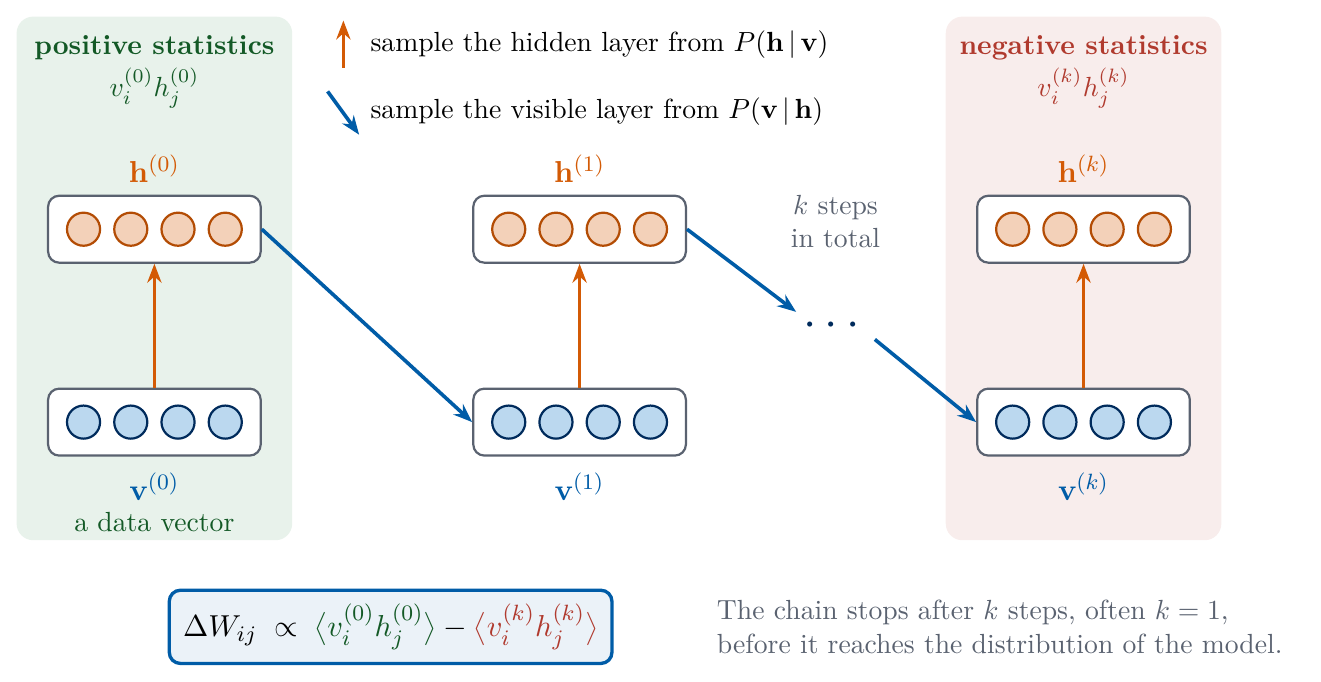

The sketch shows the chain from the data vector $\mathbf v^{(0)}$ to $\mathbf v^{(k)}$. It writes the two terms of the update with sampled hidden units $h_j^{(0)}$ and $h_j^{(k)}$, and the update (14) uses the probabilities (7) in their place, which has the same mean and less noise. The sketch mentions the common choice $k=1$, whereas we train the large machine with $k=5$.

The first term of the update (14) is the positive phase of equation (12). The approximation lies in the second term, where $\mathbf v^{(k)}$ takes the place of a sample of the model. After a few steps the chain is still correlated with the training configuration from which it started, so the average of the update (14) differs systematically from the gradient (12). This difference is called the bias of contrastive divergence. In general, training therefore does not converge to the maximum of the likelihood and the bias vanishes only for $k\to\infty$ [3,7]. The update raises the energy where the short chains arrive, which is close to the data. A region of high model probability far from the data is not reached by these chains, and its energy is not raised.

For the small machine the bias can be computed without sampling noise. One sampling step is described by the $16\times16$ matrix of the probabilities to go from $\mathbf v$ to $\mathbf v'$, and the distribution of $\mathbf v^{(k)}$ is the distribution of the data multiplied $k$ times by this matrix. We evaluate the update (14) averaged over all chains in this way, compare it with the gradient (12) at the random parameters of Section 3, and then repeat the training of Section 4 with CD-1 and CD-5 in place of the gradient. Panel (a) of the figure shows the deviation from the gradient against $k$ and panel (b) the three training runs.

In the next cell `transition_matrix` builds the matrix of shape `(16, 16)` from the table $p(\mathbf v,\mathbf h)$. Its entry $(\mathbf v,\mathbf v')$ is $\sum_{\mathbf h}P(\mathbf h|\mathbf v)P(\mathbf v'|\mathbf h)$. The function `chain_distribution` multiplies the distribution of the data by the $k$-th power of this matrix, which gives the distribution of $\mathbf v^{(k)}$, and `train_tiny(k)` uses it in place of the model distribution.

the model distribution is unchanged by one sampling step: largest deviation 1.4e-17
relative deviation of the CD-k update from the exact gradient at the random parameters:
   k = 1: 9.0e-02,  k = 2: 1.3e-02,  k = 3: 2.0e-03,  k = 5: 4.2e-05,  k = 10: 2.9e-09,  k = 20: 1.5e-15
exact gradient: D_KL after 100 steps 0.2903, 300 steps 0.0251, 1000 steps 0.0122, 3000 steps 0.0087 nats
          CD-1: D_KL after 100 steps 0.5055, 300 steps 0.1657, 1000 steps 0.0223, 3000 steps 0.0110 nats
          CD-5: D_KL after 100 steps 0.2975, 300 steps 0.0325, 1000 steps 0.0126, 3000 steps 0.0089 nats


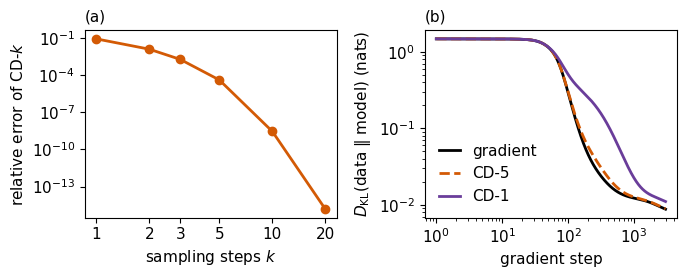

In [12]:
def transition_matrix(a, c, W):
    # probability that one alternating sampling step leads from the visible configuration v (row) to v' (column)
    P = joint_distribution(a, c, W)
    # P / P.sum(1) is P(h|v), shape (16, 8), rows v. (P / P.sum(0)).T is P(v'|h), shape (8, 16), rows h and columns v'.
    return (P / P.sum(1, keepdims=True)) @ (P / P.sum(0, keepdims=True)).T   # sum over h of P(h|v) P(v'|h)

def chain_distribution(a, c, W, k):
    # p_data is a row vector, so p_data @ T^k is the distribution of v^(k) after k steps from the data, shape (16,)
    return p_data @ np.linalg.matrix_power(transition_matrix(a, c, W), k)

p_model_t = P_joint.sum(1)                                   # p(v) at the random parameters of Section 3
dev_stationary = np.abs(p_model_t @ transition_matrix(a_t, c_t, W_t) - p_model_t).max()
print(f"the model distribution is unchanged by one sampling step: largest deviation {dev_stationary:.1e}")

K_TINY = (1, 2, 3, 5, 10, 20)
cd_error = []
for k in K_TINY:
    positive, negative = two_phases(a_t, c_t, W_t, chain_distribution(a_t, c_t, W_t, k))
    update = flatten(positive) - flatten(negative)           # averaged CD-k update
    cd_error.append(np.linalg.norm(update - grad_formula) / np.linalg.norm(grad_formula))
print("relative deviation of the CD-k update from the exact gradient at the random parameters:")
print("   " + ",  ".join(f"k = {k}: {err:.1e}" for k, err in zip(K_TINY, cd_error)))

CHECKPOINTS = (100, 300, 1000, 3000)
kl_cd = {"exact": kl_exact}
for k in (1, 5):
    _, trace_cd = train_tiny(k)                              # training with the CD-k update
    kl_cd[k] = -entropy_data - trace_cd["ell"]               # the log-likelihood itself is evaluated exactly
for name, kl in kl_cd.items():
    label = "exact gradient" if name == "exact" else f"CD-{name}"
    print(f"{label:>14}: D_KL after " + ", ".join(f"{c} steps {kl[c]:.4f}" for c in CHECKPOINTS) + " nats")
plot_cd_small(K_TINY, cd_error, kl_cd, STEPS_TINY)

Panel (a) shows the relative deviation of the averaged CD-$k$ update from the gradient, measured by the Euclidean norm over the 19 parameters. It is $0.09$ for $k=1$ and $0.013$ for $k=2$, and it falls below $10^{-4}$ at $k=5$. Panel (b) shows $D_{\rm KL}$ from the data to the model during training on double-logarithmic axes, for the gradient (12) and for the two CD updates. CD-5 follows the curve of the gradient closely. CD-1 learns more slowly, with $D_{\rm KL}=0.17$ nats after 300 steps against $0.025$ for the gradient and $0.033$ for CD-5, and after 3000 steps all three lie between $0.009$ and $0.011$ nats.

In this machine of seven units a chain forgets its start within a few steps, so a small $k$ suffices. For 100 visible units this no longer holds, and Section 7 shows that for the Ising data below $T_c$ many chains keep the sign of their initial magnetisation for 1000 steps.

## 6. Training on the Ising configurations

We train one machine on the 10 000 configurations at $T=2.0$ and one on those at $T=3.0$. Each has $N=100$ visible units, one per lattice site, and $M=64$ hidden units, which gives 6564 parameters. The 64 hidden units are well below the 200 of the exact construction of Section 3, so the machine has to compress the data, and training one machine takes well below a minute. We use CD-5, mini-batches of 100 configurations, the step size $\eta=0.1$ and 100 passes through the data, called epochs, which amounts to 10 000 updates. The biases start at zero and the weights at small random values. These settings were chosen by us and are the same for both temperatures.

The next cell defines the sampling. The visible layer `v` has shape `(B, N)` and the hidden layer `h` has shape `(B, M)`, where $B$ is the number of chains that run side by side. The functions `hidden_probability` and `visible_probability` implement equations (7) and (8) for all chains and all units at once. The function `sample` compares one uniform random number per unit with its probability, which yields 1 with that probability and 0 otherwise. The function `gibbs_step` performs one alternating sampling step.

In [13]:
def hidden_probability(params, v):
    a, c, W = params
    return sigmoid(c + v @ W)                                # P(h_j = 1 | v), equation (7), shape (B, M)

def visible_probability(params, h):
    a, c, W = params
    return sigmoid(a + h @ W.T)                              # P(v_i = 1 | h), equation (8), shape (B, N)

def sample(probability, rng):
    # one uniform random number per entry; the comparison is True with the given probability
    return (rng.random(probability.shape, dtype=np.float32) < probability).astype(np.float32)

def gibbs_step(params, v, rng):
    # one alternating sampling step: all hidden units given v, then all visible units given h
    h = sample(hidden_probability(params, v), rng)
    return sample(visible_probability(params, h), rng)

The function `cd_update` applies the update (14) to one mini-batch `v_data` of shape `(B, N)`. It returns the new parameters, the fraction of units in which $\mathbf v^{(k)}$ differs from $\mathbf v^{(0)}$, and the fractions of chains whose sign of the magnetisation changed in each direction during the $k$ steps. The product `v_data.T @ ph_data` has shape `(N, M)`, and dividing it by $B$ gives the mini-batch average of $v_iP(h_j=1|\mathbf v)$ for all pairs $(i,j)$. The function `train_rbm` loops over the epochs. In each epoch it shuffles the configurations and cuts them into mini-batches. With `track_signs=True` it also records after each epoch the difference of the mean free energies (8a) of the data with $m>0$ and with $m<0$. These diagnostics use no random numbers, so they do not change the training.

In [14]:
def magnetisation_sign(v):
    # s = 1 - 2 v, so m > 0 means that fewer than half of the units equal 1; shape (B,)
    return np.sign(0.5 - v.mean(1))

def cd_update(params, v_data, k, eta, rng):
    a, c, W = params
    v_model = v_data                                         # the chain starts at the data, v^(0)
    for _ in range(k):
        v_model = gibbs_step(params, v_model, rng)           # after the loop this is v^(k)
    ph_data = hidden_probability(params, v_data)             # P(h_j = 1 | v^(0)), shape (B, M)
    ph_model = hidden_probability(params, v_model)           # P(h_j = 1 | v^(k)), shape (B, M)
    # data average minus chain average, equation (14); mean(0) averages over the mini-batch
    a = a + eta * (v_data - v_model).mean(0)
    c = c + eta * (ph_data - ph_model).mean(0)
    positive_phase = v_data.T @ ph_data                      # sum over the mini-batch of v_i P(h_j = 1 | v), shape (N, M)
    negative_phase = v_model.T @ ph_model
    W = W + eta * (positive_phase - negative_phase) / len(v_data)

    sign_start, sign_end = magnetisation_sign(v_data), magnetisation_sign(v_model)
    to_negative = np.mean((sign_start > 0) & (sign_end < 0)) # fraction of the chains going from m > 0 to m < 0
    to_positive = np.mean((sign_start < 0) & (sign_end > 0))
    return (a, c, W), np.mean(v_data != v_model), to_negative, to_positive

def train_rbm(V, n_hidden, k, epochs, eta, batch=100, seed=79, track_signs=False):
    rng = np.random.default_rng(seed)
    V = np.asarray(V, np.float32)                            # single precision, shape (D, N)
    params = (np.zeros(V.shape[1], np.float32), np.zeros(n_hidden, np.float32),
              (0.01 * rng.standard_normal((V.shape[1], n_hidden))).astype(np.float32))   # a = 0, c = 0, small random W
    sign_of_data = magnetisation_sign(V)
    log = dict(changed=[], to_negative=[], to_positive=[], free_energy_gap=[])
    for _ in range(epochs):                                  # one epoch is one pass through the shuffled data
        per_batch = []
        # permutation gives the indices in random order, and reshape(-1, batch) cuts them into rows of length `batch`
        for rows in rng.permutation(len(V)).reshape(-1, batch):
            params, changed, to_negative, to_positive = cd_update(params, V[rows], k, eta, rng)
            per_batch.append((changed, to_negative, to_positive))
        changed, to_negative, to_positive = np.mean(per_batch, axis=0)   # averages over the mini-batches of this epoch
        log["changed"].append(changed); log["to_negative"].append(to_negative); log["to_positive"].append(to_positive)
        if track_signs:
            F = free_energy(params, V)                       # equation (8a), shape (D,)
            log["free_energy_gap"].append(float(F[sign_of_data > 0].mean() - F[sign_of_data < 0].mean()))
    return params, {name: np.array(values) for name, values in log.items()}

The log-likelihood (9) contains $Z$ and cannot be monitored for 100 units. During training we record the fraction of visible units in which $\mathbf v^{(k)}$ differs from $\mathbf v^{(0)}$. This number alone is hard to read, so we compare it with a reference. Two independent configurations of the data with the same sign of the magnetisation also differ in a certain fraction of their units. If unit $i$ equals 1 with the frequency $f_i$ among configurations of one sign, two independent configurations differ at this unit with the probability $2f_i(1-f_i)$, and the function `independent_difference` averages this over the units and over the two signs. A chain that has kept the sign of its start and forgotten everything else reaches this reference. This curve cannot certify that learning succeeded, because it stays low for a machine that resamples a typical configuration of the right sign and says nothing about the distribution of these configurations. The tests of learning are the generated configurations of Sections 7 and 8. The next cell trains both machines and evaluates the reference.

T = 2.0: 100 epochs x 100 updates with CD-5 in 27.4 s; fraction of units changed by the chain 0.387 -> 0.084; two independent same-sign data configurations differ in 0.085
T = 3.0: 100 epochs x 100 updates with CD-5 in 26.6 s; fraction of units changed by the chain 0.500 -> 0.379; two independent same-sign data configurations differ in 0.461
parameters of each machine: 6564


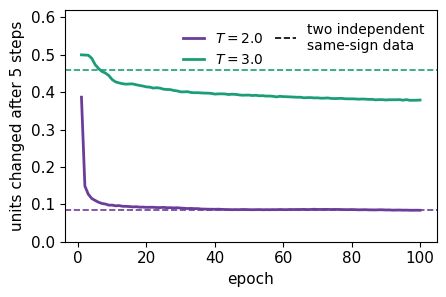

In [15]:
def independent_difference(V, m):
    # expected fraction of differing units for two independent data configurations of the same sign of m
    parts, weights = [], []
    for side in (m > 0, m < 0):                              # boolean masks that select one sign
        f = V[side].mean(0)                                  # frequency of unit value 1, shape (N,)
        parts.append(np.mean(2 * f * (1 - f)))
        weights.append(side.mean())
    return float(np.average(parts, weights=weights))

N_HIDDEN, CD_K, EPOCHS, ETA, BATCH = 64, 5, 100, 0.1, 100
RBM, TRAIN_LOG, CHANGED, SAME_SIGN_REFERENCE = {}, {}, {}, {}
for T in (T_LOW, T_HIGH):
    t0 = time.perf_counter()
    RBM[T], TRAIN_LOG[T] = train_rbm(to_units(SPINS[T]), N_HIDDEN, CD_K, EPOCHS, ETA, BATCH, track_signs=True)
    CHANGED[T] = TRAIN_LOG[T]["changed"]
    SAME_SIGN_REFERENCE[T] = independent_difference(to_units(SPINS[T]), DATA_OBS[T]["m"])
    print(f"T = {T}: {EPOCHS} epochs x {len(SPINS[T]) // BATCH} updates with CD-{CD_K} in {time.perf_counter() - t0:.1f} s;"
          f" fraction of units changed by the chain {CHANGED[T][0]:.3f} -> {CHANGED[T][-1]:.3f};"
          f" two independent same-sign data configurations differ in {SAME_SIGN_REFERENCE[T]:.3f}")
n_parameters = N * N_HIDDEN + N + N_HIDDEN                   # weights + visible biases + hidden biases
print(f"parameters of each machine: {n_parameters}")
plot_training(CHANGED, SAME_SIGN_REFERENCE, CD_K)

The figure shows, for every epoch, the fraction of visible units that five sampling steps change, averaged over the mini-batches of the epoch, and the dashed lines mark the reference for two independent data configurations of the same sign. In the first epoch this fraction is $0.50$ at $T=3.0$ and $0.39$ at $T=2.0$, and it averages over 100 updates during which the machine is still learning. During training it settles at $0.08$ for $T=2.0$ and at $0.38$ for $T=3.0$. At $T=2.0$ the final value $0.084$ agrees with the reference $0.085$. Five steps therefore change as many units as a replacement by an unrelated configuration of the same sign would, so a small fraction of changed units does not show that a chain stays near its start. At $T=3.0$ the value lies below the reference $0.46$, so some memory of the start remains after five steps.

To see how fast a chain forgets its start we run the trained machines from 2000 data configurations for 1000 sampling steps. The function `generate` runs such chains. Its input is the machine, the number of steps, a seed and, when a start is given, the starting configurations, of shape `(chains, N)`. Without a start it draws every unit as 0 or 1 with probability one half. On request it records the sign of the magnetisation of every chain after every step, in an array of shape `(steps + 1, chains)`, and the fraction of units that differ from the start at chosen steps.

T = 2.0: units changed after k steps from the data: k = 1: 0.076, k = 2: 0.079, k = 3: 0.080, k = 5: 0.082, k = 10: 0.082, k = 20: 0.087, k = 50: 0.097, k = 100: 0.111, k = 300: 0.179, k = 1000: 0.321; same-sign reference 0.085
T = 3.0: units changed after k steps from the data: k = 1: 0.250, k = 2: 0.304, k = 3: 0.336, k = 5: 0.377, k = 10: 0.427, k = 20: 0.467, k = 50: 0.492, k = 100: 0.493, k = 300: 0.501, k = 1000: 0.497; same-sign reference 0.461


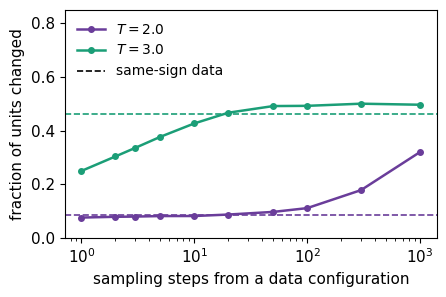

In [16]:
N_GEN, N_GIBBS = 2000, 1000
WATCH_STEPS = (1, 2, 3, 5, 10, 20, 50, 100, 300, 1000)

def generate(params, n_steps, seed, start=None, keep_signs=False, watch_steps=()):
    rng = np.random.default_rng(seed)
    v = sample(np.full((N_GEN, N), 0.5, np.float32), rng) if start is None else np.asarray(start, np.float32)
    v_start = v
    signs = [np.sign(to_spins(v).mean(1)).astype(np.int8)] if keep_signs else None   # sign of m for every chain
    changed = {}
    for step in range(1, n_steps + 1):
        v = gibbs_step(params, v, rng)
        if keep_signs:
            signs.append(np.sign(to_spins(v).mean(1)).astype(np.int8))
        if step in watch_steps:
            changed[step] = float(np.mean(v != v_start))
    return to_spins(v).reshape(len(v), L, L), (np.array(signs) if keep_signs else None), changed

FROM_DATA, SIGNS_FROM_DATA, MEMORY = {}, {}, {}
for T in (T_LOW, T_HIGH):
    start = to_units(SPINS[T][:N_GEN])                       # the first 2000 data configurations
    FROM_DATA[T], SIGNS_FROM_DATA[T], MEMORY[T] = generate(RBM[T], N_GIBBS, seed=279, start=start, keep_signs=True, watch_steps=WATCH_STEPS)
    print(f"T = {T}: units changed after k steps from the data: " + ", ".join(f"k = {k}: {MEMORY[T][k]:.3f}" for k in WATCH_STEPS)
          + f"; same-sign reference {SAME_SIGN_REFERENCE[T]:.3f}")
plot_chain_memory(MEMORY, SAME_SIGN_REFERENCE)

The figure shows the fraction of units that differ from the starting data configuration against the number of sampling steps, on a logarithmic axis, and the dashed lines repeat the references. At $T=2.0$ a single step already changes $0.076$ of the units, close to the reference $0.085$, and the curve stays near it for tens of steps. A chain therefore reaches, within very few steps, the fraction of changed units of an independent configuration of the same sign, while the overall sign is kept. The slow rise at many steps comes from chains that reverse their magnetisation, which Section 7 follows. At $T=3.0$ the curve climbs gradually from $0.25$ after one step through $0.38$ after five and reaches the reference within about 20 steps. It then approaches $0.50$, the value for two configurations without any relation, because these chains also lose the sign of their start.

## 7. Generated configurations

A trained machine generates configurations by the alternating sampling of Section 5, now without any data. We start 2000 chains from random units, each unit being 0 or 1 with probability one half, run 1000 sampling steps, and keep the final visible layer, mapped back to spins by $s_i=1-2v_i$. For every generated configuration we evaluate the magnetisation and the energy (3) with the Ising energy (1), which the machine has never been given.

In the next cell `compare` turns an array of generated configurations of shape `(chains, L, L)` into the observables and sets them beside those of the data. The dictionaries `STAT` and `STAT_FROM_DATA` hold the results for the chains started from random units and for the chains of Section 6 started from data. The figure shows six configurations of the data and the first six generated configurations at each temperature, without any selection, with the magnetisation of each configuration below it.

T = 2.0: 2000 chains x 1000 steps in 6.4 s
   <|m|>  generated 0.907  data 0.911
   <e>    generated -1.660  data -1.746   | spread of e  generated 0.169  data 0.170
   fraction with m > 0: generated 0.0065  data 0.50
   chains started from data: fraction with m > 0 0.50 at the start, 0.21 after 1000 steps; <|m|> 0.912, <e> -1.682
T = 3.0: 2000 chains x 1000 steps in 6.1 s
   <|m|>  generated 0.260  data 0.275
   <e>    generated -0.738  data -0.824   | spread of e  generated 0.221  data 0.198
   fraction with m > 0: generated 0.5340  data 0.49
   chains started from data: fraction with m > 0 0.49 at the start, 0.55 after 1000 steps; <|m|> 0.255, <e> -0.738
T = 2.0: magnetisation of the six configurations in the figure: [-0.9  -0.88 -0.86  0.92 -0.9  -0.82]
   13 of 2000 chains have m > 0, the first of them with index 3; six chains contain at least one of them with probability 0.038


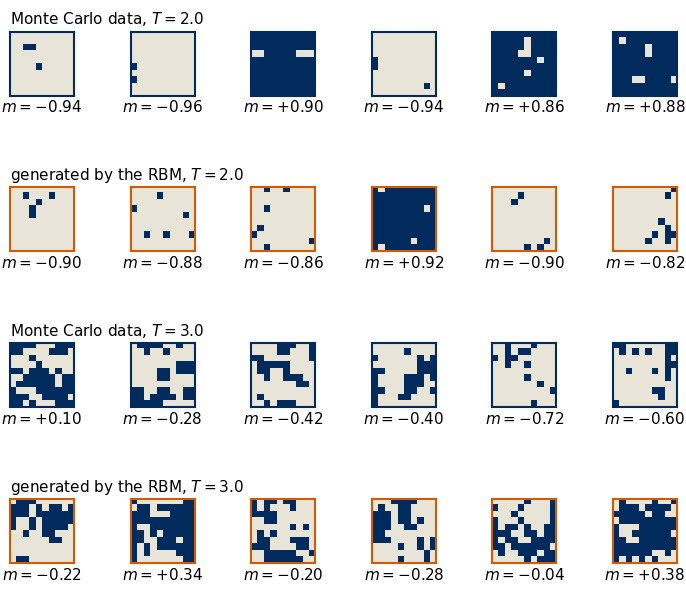

In [18]:
def compare(generated, T):
    m, e = magnetisation(generated), energy_per_spin(generated)
    d = DATA_OBS[T]
    return dict(m=m, e=e, abs_m=float(np.abs(m).mean()), abs_m_data=float(np.abs(d["m"]).mean()), e_mean=float(e.mean()),
                e_data=float(d["e"].mean()), e_std=float(e.std()), e_std_data=float(d["e"].std()),
                fraction_positive=float(np.mean(m > 0)), fraction_positive_data=float(np.mean(d["m"] > 0)))

GEN, SIGNS_RANDOM, STAT, STAT_FROM_DATA = {}, {}, {}, {}
for T in (T_LOW, T_HIGH):
    t0 = time.perf_counter()
    GEN[T], SIGNS_RANDOM[T], _ = generate(RBM[T], N_GIBBS, seed=179, keep_signs=True)   # chains started from random units
    STAT[T] = compare(GEN[T], T)
    STAT_FROM_DATA[T] = compare(FROM_DATA[T], T)             # chains of Section 6, started from data configurations
    s, f = STAT[T], STAT_FROM_DATA[T]
    print(f"T = {T}: {N_GEN} chains x {N_GIBBS} steps in {time.perf_counter() - t0:.1f} s")
    print(f"   <|m|>  generated {s['abs_m']:.3f}  data {s['abs_m_data']:.3f}")
    print(f"   <e>    generated {s['e_mean']:.3f}  data {s['e_data']:.3f}   | spread of e  generated {s['e_std']:.3f}  data {s['e_std_data']:.3f}")
    print(f"   fraction with m > 0: generated {s['fraction_positive']:.4f}  data {s['fraction_positive_data']:.2f}")
    print(f"   chains started from data: fraction with m > 0 {np.mean(magnetisation(SPINS[T][:N_GEN]) > 0):.2f} at the start,"
          f" {f['fraction_positive']:.2f} after {N_GIBBS} steps; <|m|> {f['abs_m']:.3f}, <e> {f['e_mean']:.3f}")

# the first six generated configurations at T = 2.0, which the figure shows without selection
m_low = STAT[T_LOW]["m"]
n_positive_low = int(np.sum(m_low > 0))
chance_in_six = 1 - (1 - n_positive_low / N_GEN) ** 6        # probability that six chains contain at least one with m > 0
print(f"T = {T_LOW}: magnetisation of the six configurations in the figure: {np.round(m_low[:6], 2)}")
print(f"   {n_positive_low} of {N_GEN} chains have m > 0, the first of them with index {int(np.argmax(m_low > 0))};"
      f" six chains contain at least one of them with probability {chance_in_six:.3f}")
plot_samples([(SPINS[T_LOW][:6], f"Monte Carlo data, $T={T_LOW}$", COL["data"]), (GEN[T_LOW][:6], f"generated by the RBM, $T={T_LOW}$", COL["model"]),
              (SPINS[T_HIGH][:6], f"Monte Carlo data, $T={T_HIGH}$", COL["data"]), (GEN[T_HIGH][:6], f"generated by the RBM, $T={T_HIGH}$", COL["model"])])

The first and third rows show Monte Carlo configurations and the second and fourth rows configurations generated by the machines from random starts, with navy for $s_i=+1$ and light squares for $s_i=-1$. At $T=3.0$ the generated configurations contain domains of both directions, as the data do. At $T=2.0$ they are ordered, as the data are, and they contain more isolated flipped spins than the data.

The fourth frame of the generated row at $T=2.0$ is navy with $m=+0.92$, although only 13 of the 2000 chains, 0.65 per cent, end with $m>0$. Since the six frames are the first six chains and the colours follow the spin values, this frame is one of the 13 rare chains, as the printed index confirms. Six chains contain at least one such chain with a probability of about 4 per cent, so one positive frame in this row is a coincidence and says nothing on the frequency of the positive sign.

For the single training run of Section 6, the mean absolute magnetisation of the generated configurations is $0.91$ at $T=2.0$ and $0.26$ at $T=3.0$, against $0.91$ and $0.28$ in the data. The mean energy per spin is $-1.66$ and $-0.74$, against $-1.75$ and $-0.82$ in the data, so at both temperatures the generated configurations lie about $0.09$ too high in energy and contain more unsatisfied bonds than the Monte Carlo configurations. Section 9 examines how this excess depends on the number of hidden units.

### Sign of the magnetisation along the chains

The sign of the magnetisation at $T=2.0$ is reproduced worst, since only 13 of the 2000 chains started from random units end with $m>0$, whereas the data contain both signs in equal parts. Of the chains started at data configurations, half begin with $m>0$ and 21 per cent have $m>0$ after 1000 steps. To understand this we follow the sign of every chain. The function `sign_statistics` takes the array of signs of shape `(steps + 1, chains)`. A chain with $m=0$ at some step keeps the previous sign, and the function then counts the chains by their sign at the start and at the end and the sign changes in each direction. The cell after it also compares the free energy (8a) of the data configurations with $m>0$ and with $m<0$, because a lower free energy means a larger probability $p(\mathbf v)$. The figure shows the fraction of chains with $m>0$ against the number of steps, separately for chains started with $m>0$, for chains started with $m<0$ and for the chains started from random units. Here a chain with $m=0$ counts as not positive.

In [19]:
def sign_statistics(signs, early_step=CD_K):
    signs = signs.astype(np.int8).copy()                     # shape (steps + 1, chains)
    for t in range(1, len(signs)):
        # np.where keeps the previous sign wherever the current magnetisation is exactly zero
        signs[t] = np.where(signs[t] == 0, signs[t - 1], signs[t])
    start, end, early = signs[0], signs[-1], signs[early_step]
    up = int(np.sum((signs[:-1] < 0) & (signs[1:] > 0)))     # changes from negative to positive, over all steps and chains
    down = int(np.sum((signs[:-1] > 0) & (signs[1:] < 0)))
    return dict(start_positive=int(np.sum(start > 0)), start_negative=int(np.sum(start < 0)), start_zero=int(np.sum(start == 0)),
                positive_stay_positive=int(np.sum((start > 0) & (end > 0))), positive_end_negative=int(np.sum((start > 0) & (end < 0))),
                negative_end_positive=int(np.sum((start < 0) & (end > 0))), negative_stay_negative=int(np.sum((start < 0) & (end < 0))),
                changes_up=up, changes_down=down,
                negative_chains_ever_positive=int(np.sum((start < 0) & np.any(signs > 0, axis=0))),
                positive_to_negative_within_cd=int(np.sum((start > 0) & (early < 0))),
                negative_to_positive_within_cd=int(np.sum((start < 0) & (early > 0))))

In [20]:
SIGN_STATS, FREE_ENERGY, SIGN_FLOW = {}, {}, {}
for T in (T_LOW, T_HIGH):
    SIGN_STATS[T] = sign_statistics(SIGNS_FROM_DATA[T])
    F_data = free_energy(RBM[T], to_units(SPINS[T]).astype(np.float32))   # free energy (8a) of the data, shape (D,)
    m = DATA_OBS[T]["m"]
    FREE_ENERGY[T] = dict(positive=float(F_data[m > 0].mean()), negative=float(F_data[m < 0].mean()))

    from_data = SIGNS_FROM_DATA[T]                           # signs, shape (steps + 1, chains)
    starts_positive = from_data[0] > 0                       # boolean mask over the chains, shape (chains,)
    starts_negative = from_data[0] < 0
    # from_data[:, mask] keeps the columns of the selected chains; (... > 0).mean(1) is the fraction positive at each step
    SIGN_FLOW[T] = dict(start_positive=(from_data[:, starts_positive] > 0).mean(1),
                        start_negative=(from_data[:, starts_negative] > 0).mean(1),
                        start_random=(SIGNS_RANDOM[T] > 0).mean(1))

T = 2.0: chains from data, 1000 steps
   start m > 0: 996 chains, of which 427 end with m > 0 and 569 with m < 0
   start m < 0: 1004 chains, of which 0 end with m > 0 and 1004 with m < 0; 0 of them ever reach m > 0; start m = 0: 0 chains
   sign changes over all steps: 589 from + to -, 20 from - to +
   sign changed after 5 steps: 4 chains from + to -, 0 from - to +
   mean free energy of the data: -249.46 for m > 0, -277.39 for m < 0
   random starts: fraction with m > 0 at step 0 0.462, step 1 0.253, step 1000 0.0065; fraction with m = 0 at step 0 0.076
T = 3.0: chains from data, 1000 steps
   start m > 0: 973 chains, of which 566 end with m > 0 and 407 with m < 0
   start m < 0: 990 chains, of which 528 end with m > 0 and 462 with m < 0; 990 of them ever reach m > 0; start m = 0: 37 chains
   sign changes over all steps: 88840 from + to -, 88964 from - to +
   sign changed after 5 steps: 143 chains from + to -, 224 from - to +
   mean free energy of the data: -142.48 for m > 0, -14

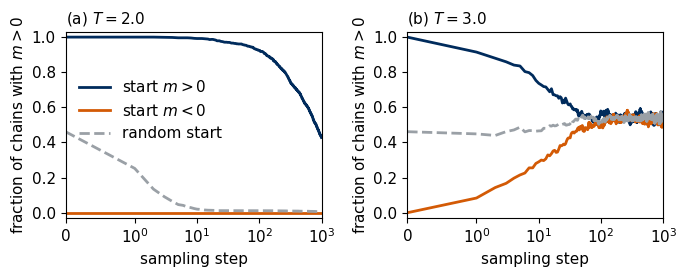

In [21]:
for T in (T_LOW, T_HIGH):
    stats = SIGN_STATS[T]
    random_flow = SIGN_FLOW[T]["start_random"]
    print(f"T = {T}: chains from data, {N_GIBBS} steps")
    print(f"   start m > 0: {stats['start_positive']} chains, of which {stats['positive_stay_positive']} end with m > 0 and {stats['positive_end_negative']} with m < 0")
    print(f"   start m < 0: {stats['start_negative']} chains, of which {stats['negative_end_positive']} end with m > 0 and {stats['negative_stay_negative']} with m < 0"
          f"; {stats['negative_chains_ever_positive']} of them ever reach m > 0; start m = 0: {stats['start_zero']} chains")
    print(f"   sign changes over all steps: {stats['changes_down']} from + to -, {stats['changes_up']} from - to +")
    print(f"   sign changed after {CD_K} steps: {stats['positive_to_negative_within_cd']} chains from + to -, {stats['negative_to_positive_within_cd']} from - to +")
    print(f"   mean free energy of the data: {FREE_ENERGY[T]['positive']:.2f} for m > 0, {FREE_ENERGY[T]['negative']:.2f} for m < 0")
    print(f"   random starts: fraction with m > 0 at step 0 {random_flow[0]:.3f}, step 1 {random_flow[1]:.3f}, step {N_GIBBS} {random_flow[-1]:.4f};"
          f" fraction with m = 0 at step 0 {np.mean(SIGNS_RANDOM[T][0] == 0):.3f}")
plot_sign_flow(SIGN_FLOW)

At $T=2.0$ the flow between the two ordered states runs in one direction. Of the 996 chains that start with $m>0$, 427 still have $m>0$ after 1000 steps and 569 have moved to $m<0$. Of the 1004 chains that start with $m<0$, none ends with $m>0$, and none reaches $m>0$ at any step. Over all chains and steps the sign changes 589 times from positive to negative and 20 times from negative to positive, and these 20 changes belong to chains that started on the positive side and returned to it for a while. The chains from random units, grey in panel (a), show the same flow towards $m<0$. The fraction with $m>0$ is $0.462$ at the start, because $7.6$ per cent of the random configurations have $m=0$ and do not count as positive. It is $0.253$ after one step and keeps falling, so the 13 positive chains at step 1000 are what remains of a fraction that is still decreasing. Neither these 13 chains nor the 21 per cent of the data starts give the equilibrium weight of the positive state in this machine.

The mean free energy (8a) of the data is $-249.5$ for configurations with $m>0$ and $-277.4$ for those with $m<0$. A typical configuration of the negative state thus has a probability larger by a factor of about $e^{28}$. This comparison concerns typical configurations and leaves the total weight of each state unmeasured, and it agrees with the direction of the flow.

These counts belong to the finished machine, on which five sampling steps change the sign of 4 of the 996 positive chains and of none of the 1004 negative ones.

At $T=3.0$ the two signs exchange freely. The chains make 88 840 sign changes from positive to negative and 88 964 in the opposite direction, five steps already change the sign of 143 positive and 224 negative chains, the curves of panel (b) merge within about a hundred steps, and the mean free energies of the two signs, $-142.5$ and $-141.8$, are close to each other. The fraction with $m>0$ is $0.53$ for the random starts and $0.55$ for the data starts, against $0.49$ in the data. With 2000 chains the statistical error of such a fraction is about $0.01$, so this machine has a small preference for $m>0$. Section 9 shows that this preference changes from one training run to another.

In [23]:
# Training on the same configurations with the two unit values exchanged: v' = 1 - v, so spin +1 is the value 1.
params_swapped, _ = train_rbm(1 - to_units(SPINS[T_LOW]), N_HIDDEN, CD_K, EPOCHS, ETA, BATCH, seed=79)
generated_swapped, _, _ = generate(params_swapped, N_GIBBS, seed=179)
# to_spins returns 1 - 2 v', which is minus the true spin s = 2 v' - 1
m_swapped = -magnetisation(generated_swapped)
print(f"T = {T_LOW}, seed 79: fraction with m > 0 is {np.mean(m_swapped > 0):.3f} with the exchanged unit values"
      f" and {STAT[T_LOW]['fraction_positive']:.4f} with the usual ones")

T = 2.0, seed 79: fraction with m > 0 is 0.998 with the exchanged unit values and 0.0065 with the usual ones


With the exchanged unit values $0.998$ of the generated configurations have $m>0$, against $0.0065$ with the usual encoding, so the favoured sign follows the encoding. Both encodings describe the same family of distributions, as stated in Section 3, so the preference comes from the training, which starts from zero biases and small weights. Section 9.2 repeats this test for three seeds.

## 8. Histograms of the magnetisation and the energy

The histograms compare the 2000 configurations generated from random starts with the 10 000 configurations of the data, first at $T=2.0$ and then at $T=3.0$. Panel (a) of each figure shows the magnetisation per spin and panel (b) the energy per spin. The data are drawn as filled bars and the generated configurations as an orange line, both normalised to unit area.

T = 3.0: fraction of configurations with |m| > 0.8: generated 0.0130, data 0.0037


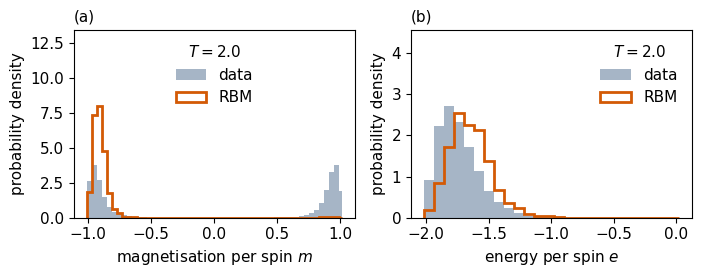

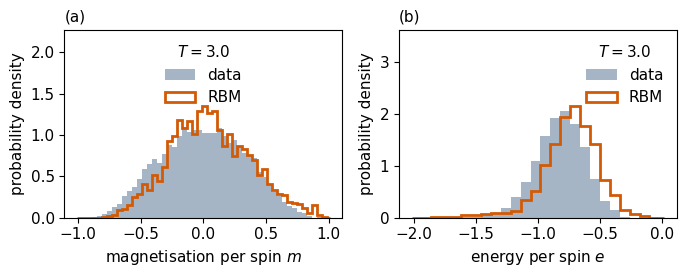

In [24]:
# m takes multiples of 0.02 and e multiples of 0.04, and every bin holds two neighbouring values (the last bin holds one)
BINS_M = np.append(np.arange(-1.01, 0.99 + 1e-9, 0.04), 1.01)
BINS_E = np.append(np.arange(-2.02, -0.02 + 1e-9, 0.08), 0.02)
for T, name in ((T_LOW, "low"), (T_HIGH, "high")):
    plot_histograms(T, name, DATA_OBS[T], STAT[T], BINS_M, BINS_E)

# weight of the two distributions at large |m| at T = 3.0, where the configurations are disordered on average
tail_generated = float(np.mean(np.abs(STAT[T_HIGH]["m"]) > 0.8))
tail_data = float(np.mean(np.abs(DATA_OBS[T_HIGH]["m"]) > 0.8))
print(f"T = {T_HIGH}: fraction of configurations with |m| > 0.8: generated {tail_generated:.4f}, data {tail_data:.4f}")

In [25]:
time_core = time.perf_counter() - started

At $T=2.0$ the magnetisation of the data, panel (a) of the first figure, has two peaks of equal weight near $m=\pm0.9$. The generated configurations reproduce the position and the width of the peak at negative $m$ and put almost no weight on the other one. Their peak is about twice as high as that of the data because each histogram has unit area and the machine puts almost all of it into one peak. The energy histogram in panel (b) has the width of the data, with a standard deviation of $0.17$ in both cases, and is shifted upwards by about $0.09$. At $T=3.0$ the generated magnetisation is broad and centred near $m=0$, as in the data, with more weight close to $m=0$ and less around $m\approx-0.4$. The energy histogram is again shifted upwards by about $0.09$ and is somewhat broader, with a standard deviation of $0.22$ against $0.20$. The generated distribution also has heavier tails, and the printed fraction of configurations with $|m|>0.8$ is $0.013$ for the machine against $0.004$ for the data.

### Summary of the core route

The energy of the RBM couples only visible with hidden units, and the conditional probabilities of one layer given the other are sigmoids of the summed inputs, the stochastic form of the sign rule of the Hopfield network. Summing out the hidden units gives the free energy (8a), through which the hidden units couple the visible units. One hidden unit per bond gives an exact representation of the Ising model, and the machines of this notebook have fewer. On the machine of seven units the conditional probabilities, the gradient as a difference of a data and a model average, and the effect of a growing number of sampling steps were all verified by enumeration.

A small RBM trained with CD-5 learns the gross features of the Ising configurations in one run per temperature. The generated configurations are ordered below $T_c$ with the correct mean of $|m|$ and contain domains above it. The distributions differ quantitatively, since the energy per spin is about $0.09$ too high at both temperatures and at $T=2.0$ almost all chains end with $m<0$. More than half of the chains that begin with $m>0$ end with the opposite sign and no chain that begins with $m<0$ reaches $m>0$. On the finished machine five sampling steps change the sign of very few chains. Exchanging the two unit values reverses the favoured sign.

The core route ends here.

## 9. Sampling steps, unit encoding, hidden units and training records (at home)

This section takes between 20 and 35 minutes, depending on the computer. Its five parts can be run separately, and Sections 9.2 to 9.5 need only the core route.

### 9.1 Number of sampling steps

The bias of contrastive divergence decreases with the number $k$ of sampling steps per update, at a cost that grows in proportion to $k$. We repeat the training of Section 6 with CD-1, CD-5 and CD-20, all other settings unchanged, and generate configurations as in Section 7 from random starts. Every setting is trained three times with different seeds of the random generator, which shows how much a result depends on the run. We also add data at $T=2.27$, next to the critical temperature, where the configurations of the $10\times10$ lattice fluctuate between ordered and disordered and $\langle|m|\rangle\approx0.76$.

The dictionary `SCAN` is indexed by the temperature, the value of $k$ and the seed. The printed table lists, for the three runs of every setting, the mean energy per spin, the mean absolute magnetisation and the fraction of generated configurations with $m>0$. The figure shows the excess of the mean energy over the data and the fraction with $m>0$ against $k$.

In [26]:
t_home = time.perf_counter()

data: T = 2.0: <|m|> 0.911, <e> -1.746, T = 2.27: <|m|> 0.758, <e> -1.479, T = 3.0: <|m|> 0.275, <e> -0.824
generated configurations, three training runs each (seeds 79, 80, 81)
T = 2.0 , CD-1 : <e> -1.657 -1.659 -1.668   <|m|> 0.907 0.906 0.911   m > 0 in 0.00 0.00 0.00
T = 2.0 , CD-5 : <e> -1.660 -1.616 -1.689   <|m|> 0.907 0.894 0.915   m > 0 in 0.01 0.00 0.00
T = 2.0 , CD-20: <e> -1.668 -1.628 -1.661   <|m|> 0.908 0.898 0.902   m > 0 in 0.17 0.14 0.32
T = 2.27, CD-1 : <e> -1.491 -1.441 -1.481   <|m|> 0.819 0.784 0.810   m > 0 in 0.01 0.03 0.02
T = 2.27, CD-5 : <e> -1.443 -1.447 -1.321   <|m|> 0.775 0.780 0.657   m > 0 in 0.12 0.08 0.36
T = 2.27, CD-20: <e> -1.352 -1.493 -1.481   <|m|> 0.694 0.813 0.808   m > 0 in 0.58 0.17 0.25
T = 3.0 , CD-1 : <e> -0.752 -0.746 -0.734   <|m|> 0.256 0.258 0.249   m > 0 in 0.54 0.43 0.48
T = 3.0 , CD-5 : <e> -0.738 -0.739 -0.748   <|m|> 0.260 0.273 0.285   m > 0 in 0.53 0.34 0.38
T = 3.0 , CD-20: <e> -0.707 -0.708 -0.715   <|m|> 0.231 0.230 0.240   

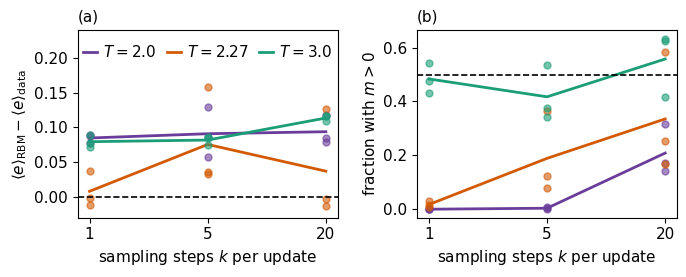

In [27]:
T_CRIT = 2.27
K_LIST, SEEDS = (1, 5, 20), (79, 80, 81)
SPINS[T_CRIT] = sample_data(T_CRIT)
DATA_OBS[T_CRIT] = dict(m=magnetisation(SPINS[T_CRIT]), e=energy_per_spin(SPINS[T_CRIT]))

SCAN = {}
MACHINES_HIGH = {}                                           # the machines trained with CD-5 at T = 3.0, used below
for T in (T_LOW, T_CRIT, T_HIGH):
    for k in K_LIST:
        for seed in SEEDS:
            if (T, k, seed) in ((T_LOW, CD_K, 79), (T_HIGH, CD_K, 79)):
                params, s = RBM[T], STAT[T]                  # this machine was already trained in Section 6
            else:
                params, _ = train_rbm(to_units(SPINS[T]), N_HIDDEN, k, EPOCHS, ETA, BATCH, seed=seed)
                s = compare(generate(params, N_GIBBS, seed=179)[0], T)
            if T == T_HIGH and k == CD_K:
                MACHINES_HIGH[seed] = params
            SCAN[T, k, seed] = {q: v for q, v in s.items() if q not in ("m", "e")}   # the summary numbers only

print(f"data: " + ", ".join(f"T = {T}: <|m|> {np.abs(DATA_OBS[T]['m']).mean():.3f}, <e> {DATA_OBS[T]['e'].mean():.3f}" for T in (T_LOW, T_CRIT, T_HIGH)))
print("generated configurations, three training runs each (seeds 79, 80, 81)")
for T in (T_LOW, T_CRIT, T_HIGH):
    for k in K_LIST:
        runs = [SCAN[T, k, seed] for seed in SEEDS]
        print(f"T = {T:<4}, CD-{k:<2d}: <e> " + " ".join(f"{r['e_mean']:.3f}" for r in runs)
              + "   <|m|> " + " ".join(f"{r['abs_m']:.3f}" for r in runs)
              + "   m > 0 in " + " ".join(f"{r['fraction_positive']:.2f}" for r in runs))
plot_steps(SCAN, (T_LOW, T_CRIT, T_HIGH), K_LIST, SEEDS)

Points are the single training runs and lines connect their means. Panel (a) shows the mean energy per spin of the generated configurations minus that of the data, with the dashed line at zero. Panel (b) shows the fraction of generated configurations with $m>0$, with the dashed line at one half. Configurations with $m=0$ are not counted as positive, so a symmetric distribution lies slightly below this line, as the value $0.49$ of the data at $T=3.0$ does.

More sampling steps do not remove the excess energy. At $T=2.0$ and $T=3.0$ every run lies between $0.06$ and $0.13$ above the data for all three values of $k$, and at $T=3.0$ the three runs with CD-20 are the highest, at about $0.11$. At $T=2.27$ the runs scatter widely. Four of the nine reproduce the mean energy of the data, $-1.48$, within $0.02$, and the others lie up to $0.16$ above it, with no order in $k$. These four runs have $\langle|m|\rangle$ between $0.81$ and $0.82$, against $0.76$ in the data, so a correct mean energy does not imply a correct magnetisation.

The balance between the two signs of the magnetisation improves with $k$ at the two lower temperatures. At $T=2.0$ the fraction with $m>0$ is at most $0.01$ in all runs with CD-1 and CD-5 and lies between $0.14$ and $0.32$ with CD-20. At $T=2.27$ it is at most $0.03$ with CD-1, between $0.08$ and $0.36$ with CD-5 and between $0.17$ and $0.58$ with CD-20. A longer chain has more opportunity to change its sign during an update, so its negative phase can contain information on the relative weight of the two ordered states. Section 9.4 follows the sign changes during training for CD-5 only, so this explanation remains untested for the other values of $k$. Even with CD-20 the three runs differ strongly from each other and none reaches one half at $T=2.0$.

At $T=3.0$ the fraction lies between $0.34$ and $0.63$ without a trend in $k$, so the value $0.53$ of Section 7 is no evidence of a balanced machine. The next cell checks whether these differences come from the training or from the sampling. It generates configurations three times, with different seeds, from each of the three machines trained with CD-5 at $T=3.0$.

In [28]:
GENERATOR_SEEDS = (179, 180, 181)
REGENERATED = {}
for training_seed, params in MACHINES_HIGH.items():
    REGENERATED[training_seed] = [float(np.mean(magnetisation(generate(params, N_GIBBS, seed=s)[0]) > 0)) for s in GENERATOR_SEEDS]
    print(f"T = {T_HIGH}, CD-{CD_K}, training seed {training_seed}: fraction with m > 0 for the generator seeds {GENERATOR_SEEDS}: "
          + " ".join(f"{x:.3f}" for x in REGENERATED[training_seed]))
print(f"statistical error of a fraction near one half with {N_GEN} independent chains: {0.5 / np.sqrt(N_GEN):.3f}")

T = 3.0, CD-5, training seed 79: fraction with m > 0 for the generator seeds (179, 180, 181): 0.534 0.556 0.530
T = 3.0, CD-5, training seed 80: fraction with m > 0 for the generator seeds (179, 180, 181): 0.342 0.342 0.348
T = 3.0, CD-5, training seed 81: fraction with m > 0 for the generator seeds (179, 180, 181): 0.376 0.383 0.389
statistical error of a fraction near one half with 2000 independent chains: 0.011


Each machine gives nearly the same fraction for the three generator seeds, between $0.53$ and $0.56$ for the training seed 79, between $0.34$ and $0.35$ for the seed 80 and between $0.38$ and $0.39$ for the seed 81. The differences between the sampling seeds reach at most a few hundredths, comparable with the statistical error of about $0.01$, whereas the three machines differ from each other by up to $0.2$. At $T=3.0$ the imbalance of the two signs is thus a property of the individual trained machine, and the trained machines do not reproduce the symmetry of the data.

### 9.2 Encoding of the spins

All machines above favour $m<0$ at $T=2.0$. The map $s_i=1-2v_i$ assigns the value $v_i=1$ to $s_i=-1$, so the state with $m<0$ has most visible units switched on and the state with $m>0$ has most of them off. In the second state the weights contribute little, because the term $v_iW_{ij}h_j$ vanishes for $v_i=0$. Section 3 showed that the two encodings describe the same family of distributions, so this asymmetry can act only through the training. We test it by training on the same configurations with the opposite encoding, $v_i'=1-v_i$, in which $s_i=+1$ is the switched-on value. If the encoding selects the favoured state, the machines should now favour $m>0$. Section 7 did this for one seed. The next cell repeats it for three seeds at $T=2.0$ with CD-5, and it trains its own reference machines with the usual encoding, so it does not depend on Section 9.1. A generated visible layer $\mathbf v'$ corresponds to the spins $s_i=2v_i'-1$, so the magnetisation has the opposite sign of the one that `magnetisation` returns after `to_spins`.

In [29]:
ENCODING_SEEDS = (79, 80, 81)
usual_units = to_units(SPINS[T_LOW])                         # s = 1 - 2 v
swapped_units = 1 - usual_units                              # v' = 1 - v, so that spin +1 is now the unit value 1
ENCODING_RUNS = {}
for seed in ENCODING_SEEDS:
    params_usual = RBM[T_LOW] if seed == 79 else train_rbm(usual_units, N_HIDDEN, CD_K, EPOCHS, ETA, BATCH, seed=seed)[0]
    params_new = params_swapped if seed == 79 else train_rbm(swapped_units, N_HIDDEN, CD_K, EPOCHS, ETA, BATCH, seed=seed)[0]
    usual_fraction = float(np.mean(magnetisation(generate(params_usual, N_GIBBS, seed=179)[0]) > 0))
    generated = generate(params_new, N_GIBBS, seed=179)[0]   # to_spins returns 1 - 2 v', which is minus the true spin
    m_true = -magnetisation(generated)
    ENCODING_RUNS[seed] = dict(fraction_positive=float(np.mean(m_true > 0)), fraction_positive_usual=usual_fraction,
                               abs_m=float(np.abs(m_true).mean()), e_mean=float(energy_per_spin(generated).mean()))
    run = ENCODING_RUNS[seed]
    print(f"seed {seed}: fraction with m > 0 is {run['fraction_positive']:.3f} with the encoding s = 2 v' - 1"
          f" and {usual_fraction:.3f} with the usual encoding s = 1 - 2 v; <|m|> {run['abs_m']:.3f}, <e> {run['e_mean']:.3f}")

seed 79: fraction with m > 0 is 0.998 with the encoding s = 2 v' - 1 and 0.006 with the usual encoding s = 1 - 2 v; <|m|> 0.907, <e> -1.662
seed 80: fraction with m > 0 is 0.997 with the encoding s = 2 v' - 1 and 0.001 with the usual encoding s = 1 - 2 v; <|m|> 0.902, <e> -1.645
seed 81: fraction with m > 0 is 0.995 with the encoding s = 2 v' - 1 and 0.004 with the usual encoding s = 1 - 2 v; <|m|> 0.903, <e> -1.648


With the opposite encoding the fraction of configurations with $m>0$ is $0.998$, $0.997$ and $0.995$ for the three seeds, whereas it is at most $0.01$ with the usual encoding. The favoured sign thus follows the encoding, and the machines favour the state in which most visible units are switched on. Their other properties remain, with $\langle|m|\rangle$ close to $0.90$ and the mean energy close to $-1.65$. Section 9.4 shows that the imbalance is already present after the first epoch and shrinks only slowly during training.

### 9.3 Number of hidden units

Section 3 showed that 200 hidden units suffice for an exact representation of the Ising distribution, whereas Section 6 used 64. We now train machines with other values of $M$, with CD-5 and the seed 79, at both temperatures. Training cannot be expected to find the exact construction, so this experiment tests how far the learned machines improve with more units. The dictionary `HIDDEN_SCAN` receives the observables of the generated configurations, and the figure shows the excess of the mean energy over the data.

T = 2.0, M =  16: excess energy per spin +0.096, <|m|> 0.908 (data 0.911), fraction with m > 0 0.003
T = 2.0, M =  32: excess energy per spin +0.103, <|m|> 0.906 (data 0.911), fraction with m > 0 0.001
T = 2.0, M =  64: excess energy per spin +0.086, <|m|> 0.907 (data 0.911), fraction with m > 0 0.006
T = 2.0, M = 128: excess energy per spin +0.002, <|m|> 0.928 (data 0.911), fraction with m > 0 0.013
T = 2.0, M = 200: excess energy per spin +0.031, <|m|> 0.917 (data 0.911), fraction with m > 0 0.002
T = 3.0, M =  16: excess energy per spin +0.238, <|m|> 0.271 (data 0.275), fraction with m > 0 0.511
T = 3.0, M =  32: excess energy per spin +0.141, <|m|> 0.263 (data 0.275), fraction with m > 0 0.401
T = 3.0, M =  64: excess energy per spin +0.086, <|m|> 0.260 (data 0.275), fraction with m > 0 0.534
T = 3.0, M = 128: excess energy per spin +0.077, <|m|> 0.247 (data 0.275), fraction with m > 0 0.457
T = 3.0, M = 200: excess energy per spin +0.044, <|m|> 0.278 (data 0.275), fraction with m 

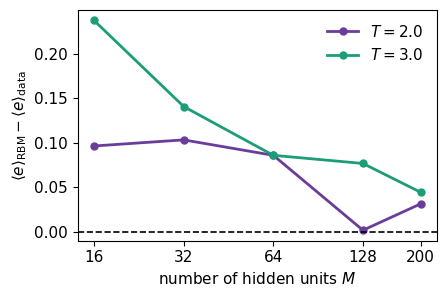

In [30]:
HIDDEN_SIZES = (16, 32, 64, 128, 200)
HIDDEN_SCAN = {}
for T in (T_LOW, T_HIGH):
    for M_units in HIDDEN_SIZES:
        if M_units == N_HIDDEN:
            s = STAT[T]                                      # the machine of Section 6
        else:
            params, _ = train_rbm(to_units(SPINS[T]), M_units, CD_K, EPOCHS, ETA, BATCH, seed=79)
            s = compare(generate(params, N_GIBBS, seed=179)[0], T)
        HIDDEN_SCAN[T, M_units] = {q: v for q, v in s.items() if q not in ("m", "e")}
        print(f"T = {T}, M = {M_units:3d}: excess energy per spin {s['e_mean'] - s['e_data']:+.3f},"
              f" <|m|> {s['abs_m']:.3f} (data {s['abs_m_data']:.3f}), fraction with m > 0 {s['fraction_positive']:.3f}")
plot_hidden_scan(HIDDEN_SCAN, HIDDEN_SIZES)

At $T=3.0$ the excess energy falls steadily with the number of hidden units, from $0.24$ for $M=16$ through $0.09$ for $M=64$ to $0.04$ for $M=200$. At $T=2.0$ it stays near $0.1$ up to $M=64$ and is close to zero for $M=128$ and $0.03$ for $M=200$. Each point is one training run, so the small differences between neighbouring values of $M$ carry little weight. The excess energy of Section 7 thus comes in part from the limited number of hidden units. With $M=200$ the excess does not vanish at $T=3.0$, so CD-5 does not find the exact construction of Section 3, although it exists for this size. The sign imbalance at $T=2.0$ remains for all values of $M$, with at most $0.013$ of the configurations at $m>0$.

### 9.4 Sign changes and free energies during training

During the training of Section 6 the function `train_rbm` recorded, for every epoch, the fraction of chains that changed sign within the five steps of an update and the difference of the mean free energies of the data with $m>0$ and $m<0$. A positive difference means that the configurations with $m<0$ are the more probable ones. The next cell prints these records and draws them.

T = 2.0: fraction of chains changing sign within 5 steps, averaged over the training: 0.00676 from + to -, 0.00057 from - to +; last 10 epochs: 0.00160 and 0.00000
   mean free energy of the data with m > 0 minus m < 0 after epochs 1, 10, 30, 100: +75.05 +96.09 +62.49 +27.93
T = 3.0: fraction of chains changing sign within 5 steps, averaged over the training: 0.10633 from + to -, 0.10100 from - to +; last 10 epochs: 0.08833 and 0.08402
   mean free energy of the data with m > 0 minus m < 0 after epochs 1, 10, 30, 100: -1.60 -1.31 -0.07 -0.65


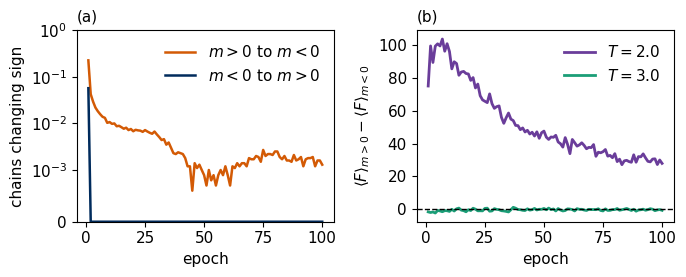

In [22]:
for T in (T_LOW, T_HIGH):
    log = TRAIN_LOG[T]
    print(f"T = {T}: fraction of chains changing sign within {CD_K} steps, averaged over the training:"
          f" {log['to_negative'].mean():.5f} from + to -, {log['to_positive'].mean():.5f} from - to +;"
          f" last 10 epochs: {log['to_negative'][-10:].mean():.5f} and {log['to_positive'][-10:].mean():.5f}")
    print("   mean free energy of the data with m > 0 minus m < 0 after epochs 1, 10, 30, 100: "
          + " ".join(f"{log['free_energy_gap'][e - 1]:+.2f}" for e in (1, 10, 30, 100)))
plot_sign_training(TRAIN_LOG)

Panel (a) shows, for $T=2.0$, the fraction of chains that change sign within the five steps of an update. Averaged over the training it is $0.68$ per cent from positive to negative and $0.057$ per cent in the opposite direction, and in the last ten epochs it is $0.16$ per cent and zero. Panel (b) shows the free-energy difference. At $T=2.0$ it is $+75$ after the first epoch, $+96$ after ten epochs, $+62$ after thirty and $+28$ at the end. The imbalance therefore appears at the very start of the training and then shrinks slowly, and it has not vanished after 100 epochs. At $T=3.0$ about 10 per cent of the chains change sign in each direction within five steps during the training, and the difference stays close to zero.

The negative phase of the update (14) sees each ordered state through chains that started in it and nearly all keep their sign, so it contains the two states in almost the same proportion as the data, whatever weights the model gives them. It therefore carries little information on their relative weight, which fits the slow decrease of the imbalance.

### The favoured sign

All machines of this notebook favour $m<0$ at $T=2.0$. With the map $s_i=1-2v_i$ this is the state in which most visible units are switched on. To test whether this encoding selects the sign, the next cell trains one machine on the same configurations with the two unit values exchanged, $v_i'=1-v_i$, so that $s_i=+1$ becomes the switched-on value, and generates configurations from random starts.

### 9.5 Learned hidden units

The weights $W_{ij}$ of one hidden unit of the machines of Section 6 form a pattern on the lattice, since the unit has one weight per site. The next cell summarises what the trained units respond to. For every hidden unit it computes the probability $P(h_j=1|\mathbf v)$ on all data configurations and its correlation with the magnetisation $m$. It also measures how many sites carry the weight of a unit, through the participation number $(\sum_iW_{ij}^2)^2/\sum_iW_{ij}^4$, and how similar the weights of neighbouring sites are, through the similarity $\sum_{\langle i,i'\rangle}W_{ij}W_{i'j}/(2\sum_iW_{ij}^2)$, where the sum runs over the bonds of the lattice. It equals one for weights that are constant over the lattice. The figure shows, for each temperature, the weights of the eight units with the largest norm, with red for positive and blue for negative weights, each on its own colour scale.

T = 2.0: median |correlation of P(h_j=1|v) with m| = 0.99, number of participating sites: median 34, smallest 16.9 of 100, median similarity of neighbouring weights = 0.90
T = 3.0: median |correlation of P(h_j=1|v) with m| = 0.44, number of participating sites: median 21, smallest 5.0 of 100, median similarity of neighbouring weights = 0.55


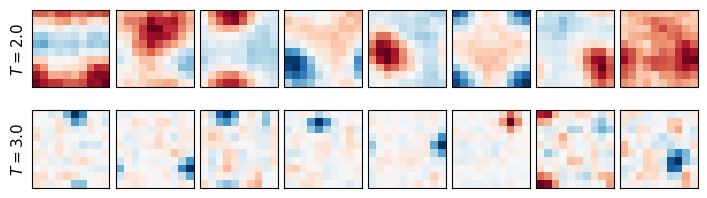

In [17]:
hidden_summary = {}
for T in (T_LOW, T_HIGH):
    W = RBM[T][2]                                            # weights, shape (N, M)
    activation = hidden_probability(RBM[T], to_units(SPINS[T]).astype(np.float32))   # shape (D, M)
    m = DATA_OBS[T]["m"]
    corr = np.array([np.corrcoef(activation[:, j], m)[0, 1] for j in range(N_HIDDEN)])   # one correlation per hidden unit
    participation = (W ** 2).sum(0) ** 2 / (W ** 4).sum(0)   # number of sites that carry the weight of each unit
    lattice_weights = W.T.reshape(N_HIDDEN, L, L)            # shape (M, L, L), one lattice per hidden unit
    # sum over the 2N bonds of W_ij W_i'j, each bond counted once through one horizontal and one vertical neighbour, as in energy_per_spin
    neighbour = (lattice_weights * np.roll(lattice_weights, 1, 1) + lattice_weights * np.roll(lattice_weights, 1, 2)).sum((1, 2))
    neighbour_similarity = neighbour / (2 * (lattice_weights ** 2).sum((1, 2)))   # 1 for perfectly smooth weights
    hidden_summary[T] = dict(median_abs_corr_with_m=float(np.median(np.abs(corr))), median_participation=float(np.median(participation)),
                             smallest_participation=float(participation.min()),
                             median_neighbour_similarity=float(np.median(neighbour_similarity)))
    print(f"T = {T}: median |correlation of P(h_j=1|v) with m| = {hidden_summary[T]['median_abs_corr_with_m']:.2f},"
          f" number of participating sites: median {hidden_summary[T]['median_participation']:.0f}, smallest {hidden_summary[T]['smallest_participation']:.1f} of {N},"
          f" median similarity of neighbouring weights = {hidden_summary[T]['median_neighbour_similarity']:.2f}")
plot_hidden_weights({T: RBM[T][2] for T in (T_LOW, T_HIGH)}, (T_LOW, T_HIGH))

The two machines use their hidden units in different ways, although neither was given the lattice. At $T=2.0$ the weights of a unit vary smoothly over the lattice, with a median similarity of neighbouring weights of $0.90$, and spread over about 34 of the 100 sites. The probability $P(h_j=1|\mathbf v)$ of a typical unit follows the magnetisation closely, with a median correlation of $0.99$ in magnitude, so these units read out the sign of the ordered state. At $T=3.0$ the largest weights concentrate on compact groups of neighbouring sites in the figure, a typical unit involves about 21 sites, the similarity of neighbouring weights is $0.55$, and the correlation with the magnetisation is only $0.44$. These units are tied to parts of the lattice, which fits the local correlations of the disordered phase, although we did not measure their response to individual domains. None of them is a bond unit of the exact construction, which would have a participation number of two, since the smallest printed values are $16.9$ at $T=2.0$ and $5.0$ at $T=3.0$.

In [31]:
if "t_home" in globals() and "SCAN" in globals() and "ENCODING_RUNS" in globals():
    time_home = time.perf_counter() - t_home

## 10. Summary of the work at home

More sampling steps per update improve the balance of the two signs at $T=2.0$ and $T=2.27$, as expected when longer chains begin to cross between the two ordered states, and they do not reduce the excess energy. The results of different training runs scatter, most strongly next to $T_c$, and at $T=3.0$ the fraction of configurations with $m>0$ is a property of each trained machine that lies between $0.34$ and $0.63$. Exchanging the two unit values reverses the sign that the machines favour at $T=2.0$, so the encoding selects which ordered state survives. The excess energy of the generated configurations decreases with the number of hidden units, from $0.24$ for $M=16$ to $0.04$ for $M=200$ at $T=3.0$, and it does not vanish even with the 200 units that would suffice for an exact representation. During training at $T=2.0$ the free energies of the two signs separate in the first epoch and approach each other only slowly, and few chains change sign within the five steps of an update. The trained hidden units at $T=2.0$ read out the sign of the magnetisation, whereas at $T=3.0$ they concentrate on compact groups of neighbouring sites.

## 11. Exercises

Each exercise has a code cell. Write your computation there, replace `None` by your result and run the cell, and the check function in the collapsed cell below reports whether it agrees. All four exercises use only the core route.

In [32]:
def check_exercise_1(p_from_free_energy):
    if p_from_free_energy is None:
        print("Exercise 1, no answer yet. Expected an array of shape (16,).")
        return
    print("Exercise 1 is correct." if np.allclose(p_from_free_energy, P_joint.sum(1)) else
          "Exercise 1 differs. Normalise exp(-F) over the 16 visible configurations and use the parameters a_t, c_t, W_t.")

def check_exercise_2(weight_for_frequency):
    if weight_for_frequency is None:
        print("Exercise 2, no answer yet. Expected a function of f.")
        return
    good = True
    for f in (0.4, 0.5, 0.7, 0.9):
        w = weight_for_frequency(f)
        gradient = f * sigmoid(w) - np.exp(w) / (3 + np.exp(w))
        good = good and abs(gradient) < 1e-9
    print("Exercise 2 is correct. The machine represents the frequencies 1/3 < f < 1." if good else
          "Exercise 2 differs. At the solution the two terms of the gradient (12) for W must be equal.")

def check_exercise_3(sampled_positive_phase):
    if sampled_positive_phase is None:
        print("Exercise 3, no answer yet. Expected a function (params, v, rng) returning an array of shape (N, M).")
        return
    v = np.asarray(to_units(SPINS[T_HIGH][:100]), np.float32)
    exact = v.T @ hidden_probability(RBM[T_HIGH], v) / len(v)
    rng_check = np.random.default_rng(3)
    samples = np.array([sampled_positive_phase(RBM[T_HIGH], v, rng_check) for _ in range(300)])
    mean_error = np.abs(samples.mean(0) - exact).max()
    noise = samples.std(0).mean()
    print(f"Exercise 3 is correct. The mean agrees with the probabilities (largest difference {mean_error:.3f}), and the sampled term fluctuates with a mean standard deviation {noise:.3f}, where the term with probabilities has none."
          if mean_error < 0.03 and noise > 0 else "Exercise 3 differs. Sample h from P(h|v) and average v_i h_j over the mini-batch.")

def check_exercise_4(fractions):
    if fractions is None:
        print("Exercise 4, no answer yet. Expected a dictionary {steps: fraction}.")
        return
    reference = {k: float(np.mean(SIGNS_FROM_DATA[T_LOW][k] > 0)) for k in (1, 10, 100, 1000)}
    good = set(fractions) == set(reference) and all(abs(fractions[k] - reference[k]) < 1e-9 for k in reference)
    print(f"Exercise 4 is correct: {reference}" if good else
          "Exercise 4 differs. Use generate(RBM[T_LOW], steps, seed=279, start=to_units(SPINS[T_LOW][:N_GEN])) for each number of steps.")

### Exercise 1. Free energy

Derive equation (8) from the energy (4) along the lines of equations (6) and (7). Then derive the free energy (8a) from equation (5) and verify it for the small machine of Section 3. Compute `F` for the 16 configurations `all_v` with `free_energy((a_t, c_t, W_t), all_v)`, turn it into probabilities and store them in `p_from_free_energy`.

In [33]:
p_from_free_energy = None

check_exercise_1(p_from_free_energy)

Exercise 1, no answer yet. Expected an array of shape (16,).


### Exercise 2. One visible and one hidden unit

An RBM with one visible and one hidden unit has $a=c=0$ and a single weight $W$. List its four configurations, compute $Z$ and $\langle vh\rangle_{\rm model}$, and find the weight at which the gradient (12) vanishes for data in which $v=1$ occurs with frequency $f$. Write the result as a function `weight_for_frequency(f)`, and state which frequencies this machine can represent.

In [34]:
weight_for_frequency = None

check_exercise_2(weight_for_frequency)

Exercise 2, no answer yet. Expected a function of f.


### Exercise 3. Sampled hidden units

The update (14) uses the probabilities $P(h_j=1|\mathbf v)$. Write a function `sampled_positive_phase(params, v, rng)` that draws the hidden units with `sample(hidden_probability(params, v), rng)` and returns the mini-batch average of $v_ih_j$, of shape `(N, M)`. The check compares its mean with the term built from probabilities and measures its fluctuations. As an extension, use it in a copy of `cd_update`, train the machine at $T=3.0$ again and compare the energy histogram with Section 8.

In [35]:
sampled_positive_phase = None

check_exercise_3(sampled_positive_phase)

Exercise 3, no answer yet. Expected a function (params, v, rng) returning an array of shape (N, M).


### Exercise 4. Sign of the magnetisation along the chains

Start the chains of Section 7 from the training configurations, with `generate(RBM[T_LOW], steps, seed=279, start=to_units(SPINS[T_LOW][:N_GEN]))`, and compute the fraction with $m>0$ after 1, 10, 100 and 1000 sampling steps. Store the results in the dictionary `fractions` with the numbers of steps as keys, and also plot $\langle e\rangle$ against the number of steps.

In [36]:
fractions = None

check_exercise_4(fractions)

Exercise 4, no answer yet. Expected a dictionary {steps: fraction}.


## References

[1] A. Dawid and Y. LeCun, Introduction to latent variable energy-based models: a path toward autonomous machine intelligence, J. Stat. Mech. (2024) 104011, doi:[10.1088/1742-5468/ad292b](https://doi.org/10.1088/1742-5468/ad292b).

[2] D. H. Ackley, G. E. Hinton and T. J. Sejnowski, A learning algorithm for Boltzmann machines, Cogn. Sci. **9**, 147 (1985), doi:[10.1207/s15516709cog0901_7](https://doi.org/10.1207/s15516709cog0901_7).

[3] G. E. Hinton, Training products of experts by minimizing contrastive divergence, Neural Comput. **14**, 1771 (2002), doi:[10.1162/089976602760128018](https://doi.org/10.1162/089976602760128018).

[4] G. Torlai and R. G. Melko, Learning thermodynamics with Boltzmann machines, Phys. Rev. B **94**, 165134 (2016), doi:[10.1103/PhysRevB.94.165134](https://doi.org/10.1103/PhysRevB.94.165134).

[5] L. Onsager, Crystal statistics. I. A two-dimensional model with an order-disorder transition, Phys. Rev. **65**, 117 (1944), doi:[10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117).

[6] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, Equation of state calculations by fast computing machines, J. Chem. Phys. **21**, 1087 (1953), doi:[10.1063/1.1699114](https://doi.org/10.1063/1.1699114).

[7] A. Fischer and C. Igel, Training restricted Boltzmann machines: an introduction, Pattern Recognit. **47**, 25 (2014), doi:[10.1016/j.patcog.2013.05.025](https://doi.org/10.1016/j.patcog.2013.05.025).

In [37]:
import re
NUMBERS = {}
home_done = "time_home" in globals() and "HIDDEN_SCAN" in globals() and "REGENERATED" in globals()
NUMBERS.update(TLow=f"{T_LOW:.1f}", THigh=f"{T_HIGH:.1f}", TLowOverTc=f"{T_LOW / T_C:.2f}", THighOverTc=f"{T_HIGH / T_C:.2f}",
               NTrain=f"{len(SPINS[T_LOW])}",
               DataAbsMLow=f"{np.abs(DATA_OBS[T_LOW]['m']).mean():.2f}", DataAbsMHigh=f"{np.abs(DATA_OBS[T_HIGH]['m']).mean():.2f}",
               DataELow=f"{DATA_OBS[T_LOW]['e'].mean():.2f}", DataEHigh=f"{DATA_OBS[T_HIGH]['e'].mean():.2f}",
               TinyLLStart=f"{trace_exact['ell'][0]:.2f}", TinyLLEnd=f"{trace_exact['ell'][-1]:.2f}", TinyLLBound=f"{-entropy_data:.2f}",
               TinyKLStart=f"{kl_exact[0]:.2f}", TinyKLEnd=f"{kl_exact[-1]:.3f}",
               TinyCDErrOne=f"{cd_error[0]:.2f}", TinyCDErrTwo=f"{cd_error[1]:.3f}", TinyCDErrFive=f"{cd_error[3]:.0e}",
               TinyKLExactThreeHundred=f"{kl_cd['exact'][300]:.3f}", TinyKLCDOneThreeHundred=f"{kl_cd[1][300]:.3f}",
               TinyKLCDFiveThreeHundred=f"{kl_cd[5][300]:.3f}", TinyKLCDOneEnd=f"{kl_cd[1][-1]:.3f}", TinyKLCDFiveEnd=f"{kl_cd[5][-1]:.3f}",
               Hidden=f"{N_HIDDEN}", GibbsK=f"{CD_K}", Epochs=f"{EPOCHS}", Parameters=f"{n_parameters}",
               ChangedLow=f"{CHANGED[T_LOW][-1]:.2f}", ChangedHigh=f"{CHANGED[T_HIGH][-1]:.2f}",
               SameSignRefLow=f"{SAME_SIGN_REFERENCE[T_LOW]:.3f}", SameSignRefHigh=f"{SAME_SIGN_REFERENCE[T_HIGH]:.2f}",
               ExactBondWeight=f"{W_bond:.2f}", ExactHiddenUnits=f"{exact_params[2].shape[1]}",
               PositiveChainsLow=f"{n_positive_low}", ChanceInSix=f"{chance_in_six:.3f}",
               StartPositiveLow=f"{SIGN_STATS[T_LOW]['start_positive']}", StayPositiveLow=f"{SIGN_STATS[T_LOW]['positive_stay_positive']}",
               StartNegativeLow=f"{SIGN_STATS[T_LOW]['start_negative']}", NegativeEndPositiveLow=f"{SIGN_STATS[T_LOW]['negative_end_positive']}",
               SignChangesDownLow=f"{SIGN_STATS[T_LOW]['changes_down']}", SignChangesUpLow=f"{SIGN_STATS[T_LOW]['changes_up']}",
               FreeEnergyPositiveLow=f"{FREE_ENERGY[T_LOW]['positive']:.1f}", FreeEnergyNegativeLow=f"{FREE_ENERGY[T_LOW]['negative']:.1f}")
for T, name in ((T_LOW, "Low"), (T_HIGH, "High")):
    s, f = STAT[T], STAT_FROM_DATA[T]
    NUMBERS.update({f"GenAbsM{name}": f"{s['abs_m']:.2f}", f"GenE{name}": f"{s['e_mean']:.2f}",
                    f"GenEStd{name}": f"{s['e_std']:.2f}", f"DataEStd{name}": f"{s['e_std_data']:.2f}",
                    f"FracPositive{name}": f"{s['fraction_positive']:.2f}", f"FracPositiveFromData{name}": f"{f['fraction_positive']:.2f}"})
NUMBERS["RuntimeCore"] = f"{time_core:.0f}"

def clean(stat):
    return {q: v for q, v in stat.items() if q not in ("m", "e")}

time_total = time.perf_counter() - started
temperatures = (T_LOW, T_CRIT, T_HIGH) if home_done else (T_LOW, T_HIGH)
summary = dict(
    experiment="restricted Boltzmann machine trained with contrastive divergence on Metropolis samples of the 10 x 10 Ising model;"
               " NumPy on CPU, RBM in float32; single training run per setting in Sections 6 to 8, three seeds per setting in Section 9",
    data=dict(source="generated in the notebook by checkerboard Metropolis sampling", lattice=L, temperatures=[T_LOW, T_HIGH],
              temperature_at_home=T_CRIT if home_done else None, T_c=float(T_C), chains=N_CHAINS_MC, sweeps_equilibration=SWEEPS_EQUIL,
              configurations_per_chain=N_KEEP, sweeps_between=SWEEPS_BETWEEN, training_configurations=int(len(SPINS[T_LOW])),
              chains_with_sign_change_between_first_and_last_stored_sweep={str(T): v for T, v in sign_changes_mc.items()},
              observables={str(T): dict(abs_m=float(np.abs(DATA_OBS[T]["m"]).mean()), e=float(DATA_OBS[T]["e"].mean()),
                                        e_std=float(DATA_OBS[T]["e"].std()), fraction_positive=float(np.mean(DATA_OBS[T]["m"] > 0)))
                           for T in temperatures}),
    exact_ising_rbm=dict(hidden_units=exact_params[2].shape[1], bond_weight_at_T_low=float(W_bond), spread_of_F_minus_H_over_T=exact_spread),
    small_machine=dict(visible=NV_TINY, hidden=NH_TINY, deviation_hidden=float(dev_h), deviation_visible=float(dev_v),
                       deviation_product=float(dev_prod), deviation_gradient=float(dev_grad), eta=ETA_TINY, steps=STEPS_TINY,
                       data="2 x 2 patch at T = 2.0", entropy_data=float(entropy_data),
                       log_likelihood_start=float(trace_exact["ell"][0]), log_likelihood_end=float(trace_exact["ell"][-1]),
                       kl_exact={str(c): float(kl_cd["exact"][c]) for c in (0,) + CHECKPOINTS},
                       kl_cd1={str(c): float(kl_cd[1][c]) for c in (0,) + CHECKPOINTS},
                       kl_cd5={str(c): float(kl_cd[5][c]) for c in (0,) + CHECKPOINTS},
                       cd_relative_error={str(k): float(err) for k, err in zip(K_TINY, cd_error)}),
    rbm=dict(hidden=N_HIDDEN, k=CD_K, epochs=EPOCHS, eta=ETA, batch=BATCH, parameters=n_parameters, chains=N_GEN, gibbs_steps=N_GIBBS,
             units_changed={str(T): np.asarray(CHANGED[T], float).tolist() for T in CHANGED},
             same_sign_reference={str(T): v for T, v in SAME_SIGN_REFERENCE.items()},
             units_changed_after_k_steps_from_data={str(T): {str(k): v for k, v in MEMORY[T].items()} for T in MEMORY},
             hidden_units={str(T): v for T, v in hidden_summary.items()},
             observables_random_start={str(T): clean(STAT[T]) for T in STAT},
             observables_data_start={str(T): clean(STAT_FROM_DATA[T]) for T in STAT_FROM_DATA},
             sign_statistics_data_start={str(T): v for T, v in SIGN_STATS.items()},
             mean_free_energy_of_data={str(T): v for T, v in FREE_ENERGY.items()},
             sign_changes_during_training={str(T): dict(to_negative_mean=float(TRAIN_LOG[T]["to_negative"].mean()), to_positive_mean=float(TRAIN_LOG[T]["to_positive"].mean()),
                                                        free_energy_gap=TRAIN_LOG[T]["free_energy_gap"].tolist()) for T in TRAIN_LOG},
             positive_chains_random_start_low=n_positive_low, tail_abs_m_above_0_8_high=dict(generated=tail_generated, data=tail_data)),
    runtime_seconds=dict(core_sections_1_8=time_core, total=time_total))

json_file, tex_file = RES / "lab079_results.json", FIG / "nb_numbers_lab079.tex"
if home_done:
    def scan_mean(T, k, quantity):
        return float(np.mean([SCAN[T, k, seed][quantity] for seed in SEEDS]))
    for T, name in ((T_LOW, "Low"), (T_CRIT, "Crit"), (T_HIGH, "High")):
        for k, kname in zip(K_LIST, ("One", "Five", "Twenty")):
            NUMBERS[f"ScanE{name}K{kname}"] = f"{scan_mean(T, k, 'e_mean'):.2f}"
            NUMBERS[f"ScanFracPositive{name}K{kname}"] = f"{scan_mean(T, k, 'fraction_positive'):.2f}"
    NUMBERS.update(TCrit=f"{T_CRIT:.2f}", DataECrit=f"{DATA_OBS[T_CRIT]['e'].mean():.2f}", DataAbsMCrit=f"{np.abs(DATA_OBS[T_CRIT]['m']).mean():.2f}",
                   RuntimeHome=f"{time_home:.0f}", EncodingFracMin=f"{min(run['fraction_positive'] for run in ENCODING_RUNS.values()):.3f}")
    summary["scan"] = {f"T={T} k={k} seed={seed}": s for (T, k, seed), s in SCAN.items()}
    summary["encoding_test"] = {str(seed): r for seed, r in ENCODING_RUNS.items()}
    summary["fraction_positive_high_by_generator_seed"] = {str(seed): v for seed, v in REGENERATED.items()}
    summary["hidden_scan"] = {f"T={T} M={M_units}": s for (T, M_units), s in HIDDEN_SCAN.items()}
    summary["runtime_seconds"]["at_home_section_9"] = time_home
if EXPORT:
    if not home_done:
        for name, value in re.findall(r"\\newcommand\{\\labseventynine(\w+)\}\{(.*)\}", tex_file.read_text()):
            NUMBERS.setdefault(name, value)
        previous = json.loads(json_file.read_text())
        for key in ("scan", "encoding_test", "fraction_positive_high_by_generator_seed", "hidden_scan"):
            if key in previous:
                summary[key] = previous[key]
    summary["numbers"] = dict(NUMBERS)
    json_file.write_text(json.dumps(summary, indent=2))
    with open(tex_file, "w") as f:
        for name, value in NUMBERS.items():
            f.write(f"\\newcommand{{\\labseventynine{name}}}{{{value.strip()}}}\n")
print(f"runtime: Sections 1-8 {time_core:.1f} s, Section 9 " + (f"{time_home:.1f} s" if home_done else "skipped") + f", total {time_total:.1f} s")

runtime: Sections 1-8 142.0 s, Section 9 1967.5 s, total 2109.5 s
